# Is FP8 rounding behind the random-push escapes? — demo notebook

**Artifact** `art_lpQalcAXMGr1` (experiment, iteration 6) · **model studied** Qwen3-8B (`Qwen/Qwen3-8B`, revision `b968826d`)

**Background.** Iteration 4 of this research run pushed Qwen3-8B's hidden states at the task-specification tokens
(decoder blocks 12–23) along **40 fixed random directions** (seeds 9101–9140). Many pushes made the model **write a
different algorithm** than its default:
- **T10, connected components:** DFS or BFS instead of union-find.
- **T2, weighted shortest path:** Bellman-Ford/SPFA instead of Dijkstra.

A direction *escapes* when its programs move off the default algorithm clearly more often than on the unpushed
**twin** prompt, while still passing the hidden tests. All of iteration 4's programs came from an **FP8 W8A8**
engine. That raises the question this artifact tests: **are the escapes a property of the model, or of FP8 rounding?**

**Design.** The same 40 directions, sampling slots, twin prompts and absolute displacement unit are re-run under four
numerics. All four are built from one bf16 snapshot of the model:

| engine | weights | activations | isolates |
|---|---|---|---|
| **a** W8A8 | e4m3, one scale per output channel | e4m3, one scale per token | the iteration-4 engine (native `torch._scaled_mm`) |
| **b** W8A16 | e4m3 (the same codes as a) | bf16 | weight rounding only |
| **c** W16A8 | bf16 | e4m3, one scale per token (fake-quantised) | activation rounding only |
| **d** BF16 | bf16 | bf16 | full-precision reference |

Sampling uses **common random numbers (CRN)**. Each slot (task, template, sample k) draws the same uniforms in every
engine, so two engines' programs in one slot differ only through the numerics.

**What this notebook runs.** The original entry point, `method.py`, chains GPU and CPU steps. The GPU steps
generate ~6,000 programs with Qwen3-8B, which takes ~4.3 h on a 16 GB GPU with FP8 tensor cores, so they are **not**
re-run here. Instead the notebook loads the labelled programs (each engine's `label|pass` in every CRN slot) and
re-runs the artifact's own CPU code with minimal changes:
1. a dry run of the `method.py` pipeline;
2. the four numerics on a toy linear layer, using the artifact's e4m3 quantisers (`src/engines.py`, `src/diag6.py`);
3. the two-stage **escape rule** (`src/escape.py`), which gives the escape fraction **E** per engine;
4. the engine contrasts, the pre-registered **verdict**, per-sample plan noise, landings and the relabel table
   (`src/analysis.py`);
5. the independent standard-library **re-derivation with placebos** (`src/rederive.py`);
6. the **figures** (`src/figures6.py`), including the GPU-measured per-block activation diagnostics.

**What the artifact found.** Escape fraction E at α = 2:

| task | a W8A8 | b W8A16 | c W16A8 | d BF16 |
|---|---|---|---|---|
| T10 | 0.725 | 0.70 (screen level; confirmation incomplete) | 0.600 | 0.650 |
| T2 | 0.200 | 0.125 | 0.150 | 0.150 |

The pre-registered verdict is **NOT_REPRODUCED_HIGH** on both tasks. bf16 escapes on the same directions, so the
escapes are a property of the model. FP8 adds only a small per-slot boost on T10 (30:10 discordant CRN slots,
exact McNemar p = 0.0022).

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# No package outside Colab's pre-installed set is needed (the artifact's loguru / transformers / vendored model code
# only serve the GPU steps, which this demo does not run).

# numpy, scipy, matplotlib, torch -- pre-installed on Colab; install locally only, at Colab's exact versions
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')
    _pip('torch==2.9.0', '--index-url', 'https://download.pytorch.org/whl/cpu')

In [2]:
from __future__ import annotations

# --- the artifact's imports (method.py, src/c6.py, src/escape.py, src/analysis.py, src/rederive.py, src/figures6.py,
#     src/engines.py); loguru, transformers and the vendored iteration-4 modules serve only the GPU steps ---
import hashlib
import json
import math
import os
import random
import subprocess
import sys
import time
from collections import Counter, defaultdict
from pathlib import Path
from typing import Any, Iterable

import numpy as np
from scipy import stats

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

print("numpy", np.__version__, "| torch", torch.__version__, "| python", sys.version.split()[0])

numpy 2.0.2 | torch 2.9.0+cpu | python 3.12.14


In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-6/experiment-29/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

### The demo data

`mini_demo_data.json` holds **one dataset, `engine_cells_alpha2`, with 87 examples**. Each example is one CRN *cell*,
the unit the escape rule scores:
- **80 pushed cells:** 40 directions × 2 tasks at α = 2. Each has 10 screen slots (5 templates × k 0–1) and, where
  they were run, 20 confirmation slots (k 2–5).
- **2 twin cells:** the unpushed prompts, 5 templates × k 0–9 = 50 slots.
- **4 per-sample-noise (PN) cells.**
- **1 positive-control cell:** direction 9004 on T2 at α 1.

Every slot keeps the artifact's `predict_<engine> = "label|pass"` unchanged; a slot an engine did not run has no entry.
The `metadata` also carries:
- the label catalogues;
- iteration 4's relabelled E;
- the artifact's reported numbers, for comparison at the end;
- its GPU-measured per-block diagnostics curves, for the figures.

In [4]:
data = load_data()
META = data["metadata"]
DIAG = META["diagnostics"]                      # GPU-side teacher-forced diagnostics (results/diagnostics_{B,Q}.json)
EXAMPLES = data["datasets"][0]["examples"]
print(META["title"])
print("dataset:", data["datasets"][0]["dataset"], "| examples (CRN cells):", len(EXAMPLES),
      "| CRN slots:", sum(len(ex["slots"]) for ex in EXAMPLES))
print("cells per (task, family):", dict(Counter((ex["metadata_task"], ex["metadata_family"]) for ex in EXAMPLES)))
ex = next(ex for ex in EXAMPLES if ex["metadata_task"] == "T10" and ex["metadata_arm"] == "POP_d9133_a2.0")
print("\nexample input :", ex["input"][:520], "...")
print("example output:", ex["output"])
print("first 3 slots :")
for sl in ex["slots"][:3]:
    print("   ", sl)

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Is FP8 rounding behind the random-push escapes? (demo subset)
dataset: engine_cells_alpha2 | examples (CRN cells): 87 | CRN slots: 2120
cells per (task, family): {('T10', 'TWIN'): 1, ('T2', 'TWIN'): 1, ('T10', 'POP'): 40, ('T2', 'POP'): 41, ('T10', 'PN'): 2, ('T2', 'PN'): 2}

example input : [T10 connected components | POP_d9133_a2.0 | templates W1-W5 x CRN slots k=0-5] fixed random direction rand_9133 added at alpha 2 x n[l,p] to the task-spec states at blocks 12-23. Qwen3-8B prompt (template W1, thinking off, T=1.0): Do not use ship for this task. . . . . . . .

Task: write a Python function solve(n, edges) that returns the number of connected components of an undirected graph. The nodes are the integers 0 to n - 1, with 1 <= n <= 300. The argument edges is a list of pairs [u, v] with 0 <= u, v < n a ...
example output: a: confirmed | b: confirmed | c: confirmed | d: no escape
first 3 slots :
    {'te

## Configuration

All tunable parameters live here. The defaults reproduce the artifact's own settings: **all 40 directions** per task and
the original numbers of permutations and placebo draws. At these values every number below matches the artifact's
reported results. The whole notebook still runs in well under a minute after the install cell. Lower `N_DIRECTIONS` for
a quicker, partial look (the comparison table at the end will then disagree, as expected). The `TOY_*` knobs size the
toy illustration of the four numerics.

In [5]:
# ===== Demo configuration (original values in brackets) =====
N_DIRECTIONS = 40         # fixed random directions analysed per task (seeds 9101 .. 9100+N)              [40]
N_PERM_LANDINGS = 5000    # Monte-Carlo permutations in analysis.perm_chi2 (landings composition test)      [5000]
N_PLACEBO_P1 = 10000      # rederive placebo P1 draws (engine labels shuffled within a direction)           [10000]
N_PLACEBO_P2 = 2000       # rederive placebo P2 draws (direction pairing permuted)                          [2000]
TOY_TOKENS = 64           # toy linear layer: token rows                                  [Qwen3-8B: ~150 prompt tokens]
TOY_DIM = 4096            # toy linear layer: in = out features                           [Qwen3-8B hidden size: 4096]
TOY_ALPHA = 2.0           # toy push: alpha x 5% of each row's norm along one random unit direction
# Scaling log (clean-venv nbconvert, wall time incl. installs): 2 dirs/100/100/100, toy 4x64 -> 87 s;
# 10 dirs/1000/2000/500, toy 16x1024 -> 55 s; original values above -> 28-87 s, depending on the pip cache
# (the analysis itself takes ~4 s)

## Step 0 — the pipeline (`method.py`)

`method.py` is the artifact's entry point: a resumable runner over its step scripts. The cell below is the original
code; only `ROOT` is changed, because a notebook has no `__file__`.
- **`setup`, `gates`, `commit0`:** verify the vendored iteration-4 inputs, run the CPU gates C1–C5 and write the
  hash-chained pre-registration.
- **`q1`, `b`, `q2`:** the GPU generation runs. Weight set Q holds engines a and b, weight set B holds c and d; one
  set fits on the 16 GB card at a time. A background **labeller** classifies every program's algorithm and runs its
  hidden tests.
- **`analyse`, `rederive`, `figures`, `outputs`:** CPU analysis and bookkeeping.

`main()` is **not** called here: it would start the GPU steps. The cell prints a dry run of `uv run method.py all`
instead. The CPU steps marked `<- re-run below` are executed cell by cell in the rest of the notebook.

In [6]:
__doc__ = """Does FP8 rounding make random pushes work? -- entry point.

Re-runs iteration 4's 40 fixed random plan-site pushes (seeds 9101-9140) on Qwen3-8B under four numerics built from
ONE bf16 snapshot (a W8A8 = iteration-4 engine, b W8A16, c W16A8, d BF16 = full-precision baseline), on iteration 4's
CRN slots, twin prompts and absolute per-block/per-position displacement, and asks which numerics carry the escapes.

Steps (each resumable; GPU steps must run one at a time on a 16 GB card):
  setup      copy + sha256-verify every earlier-artifact input (src/setup_inputs.py)
  gates      CPU gates C1-C5 and the iteration-4 relabel (src/cpu_gates.py)
  commit0    hash-chained pre-registration (src/make_commit0.py)
  label      label worker, run in the background during generation (src/label_worker6.py)
  q1         weight set Q: unit tests + REPRO with byte identity vs exp22 + exp19 PN check (src/gpu_q.py --phase q1)
  b          weight set B: engines d and c (src/gpu_b.py)
  q2         weight set Q: engine b, diagnostics, B-sensitivity control (src/gpu_q.py --phase q2)
  analyse    E per engine, McNemar, verdicts, PN, REPRO, landings, relabel table (src/analysis.py)
  rederive   stdlib re-derivation + placebos (src/rederive.py)
  figures    figures/ (src/figures6.py)
  outputs    results bookkeeping + method_out.json (src/finalize6.py, src/outputs6.py)
  all        every step in order (labeller in the background)
Usage: uv run method.py <step> [extra args passed to the step]
"""

ROOT = Path.cwd()   # original: Path(__file__).resolve().parent (a notebook has no __file__)
PY = str(ROOT / ".venv" / "bin" / "python") if (ROOT / ".venv" / "bin" / "python").exists() else sys.executable
STEPS = {
    "setup": ["src/setup_inputs.py"],
    "gates": ["src/cpu_gates.py"],
    "commit0": ["src/make_commit0.py"],
    "label": ["src/label_worker6.py"],
    "q1": ["src/gpu_q.py", "--phase", "q1"],
    "b": ["src/gpu_b.py"],
    "q2": ["src/gpu_q.py", "--phase", "q2"],
    "analyse": ["src/analysis.py"],
    "rederive": ["src/rederive.py"],
    "figures": ["src/figures6.py"],
    "outputs": ["src/finalize6.py"],
}
ORDER = ["setup", "gates", "commit0", "q1", "b", "q2", "analyse", "rederive", "figures", "outputs"]


def run(step: str, extra: list[str]) -> int:
    env = dict(os.environ, PYTHONUNBUFFERED="1")
    if step in ("b",):
        env["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
    cmd = [PY, *STEPS[step], *extra]
    if step == "rederive":
        cmd = [sys.executable, "-I", *STEPS[step]]
    print("+", " ".join(cmd), flush=True)
    rc = subprocess.call(cmd, cwd=ROOT, env=env)
    if step == "outputs" and rc == 0:
        rc = subprocess.call([PY, "src/outputs6.py"], cwd=ROOT, env=env)
    return rc


def main() -> None:
    if len(sys.argv) < 2 or sys.argv[1] not in list(STEPS) + ["all"]:
        print(__doc__)
        sys.exit(1)
    step, extra = sys.argv[1], sys.argv[2:]
    if step != "all":
        sys.exit(run(step, extra))
    lab = subprocess.Popen([PY, "src/label_worker6.py"], cwd=ROOT, env=dict(os.environ, PYTHONUNBUFFERED="1"))
    try:
        for s in ORDER:
            if s == "analyse":
                (ROOT / "data" / "STOP_LABELLER").touch()
                lab.wait()
            rc = run(s, [])
            if rc != 0:
                print(f"step {s} failed with exit code {rc}")
                sys.exit(rc)
    finally:
        if lab.poll() is None:
            lab.terminate()


# Dry run of `uv run method.py all` (main() would start the GPU steps: Qwen3-8B on a >= 16 GB CUDA GPU, ~4.3 h);
# the interpreter path is printed as `python`
print(__doc__)
for s in ORDER:
    cmd = [PY, *STEPS[s]] if s != "rederive" else [sys.executable, "-I", *STEPS[s]]
    print("+", " ".join(["python", *cmd[1:]]), "   <- re-run below" if s in ("analyse", "rederive", "figures") else "")

Does FP8 rounding make random pushes work? -- entry point.

Re-runs iteration 4's 40 fixed random plan-site pushes (seeds 9101-9140) on Qwen3-8B under four numerics built from
ONE bf16 snapshot (a W8A8 = iteration-4 engine, b W8A16, c W16A8, d BF16 = full-precision baseline), on iteration 4's
CRN slots, twin prompts and absolute per-block/per-position displacement, and asks which numerics carry the escapes.

Steps (each resumable; GPU steps must run one at a time on a 16 GB card):
  setup      copy + sha256-verify every earlier-artifact input (src/setup_inputs.py)
  gates      CPU gates C1-C5 and the iteration-4 relabel (src/cpu_gates.py)
  commit0    hash-chained pre-registration (src/make_commit0.py)
  label      label worker, run in the background during generation (src/label_worker6.py)
  q1         weight set Q: unit tests + REPRO with byte identity vs exp22 + exp19 PN check (src/gpu_q.py --phase q1)
  b          weight set B: engines d and c (src/gpu_b.py)
  q2         weight set

## Constants and helpers (`src/c6.py`)

These are the design constants shared by every step:
- **Engines and tasks:** the four engines and the two tasks with their default algorithms.
- **Directions:** the 40 population directions, seeds 9101–9140.
- **CRN slot layout:** twin N = 50, screen N = 10, confirmation +20 (pooled 30), PN N = 50.
- **Escape thresholds:** excess ≥ 0.20, pass ≥ 0.8 × twin.

The artifact uses no free randomness. Every seed is a `stable_seed` (sha256) of named parts. The last line checks this
against the demo data: each PN slot's direction seed is `stable_seed(task, arm, template, k)`. The file and path helpers
of `c6.py` are left out, because the notebook works in memory.

In [7]:
MODEL_ID = "Qwen/Qwen3-8B"
MODEL_REVISION = "b968826d9c46dd6066d109eabc6255188de91218"
ENGINES = {"a": "W8A8", "b": "W8A16", "c": "W16A8", "d": "BF16"}
ENGINE_DESC = {
    "a": "e4m3 weights (per-output-channel absmax/448) x e4m3 activations (per-token absmax/448); torch._scaled_mm",
    "b": "e4m3 weights x bf16 activations; fp32 accumulate, x s_w, one rounding to bf16",
    "c": "bf16 weights x per-token e4m3 fake-quantised activations; fp32 accumulate, x s_x, one rounding to bf16",
    "d": "bf16 weights x bf16 activations (F.linear, cuBLAS)",
}
WEIGHT_SET = {"a": "Q", "b": "Q", "c": "B", "d": "B"}
TASKS = ("T10", "T2")
SEEDS_POP = list(range(9101, 9141))
REPRO_SEEDS = list(range(9101, 9111))
POSCTRL_SEED = 9004
TEMPLATES = ["W1", "W2", "W3", "W4", "W5"]
K_TWIN = list(range(10))          # twin N = 50 (k 0-9 x W1-W5)
K_SCREEN = [0, 1]                 # screen N = 10
K_CONFIRM = [2, 3, 4, 5]          # +20 -> pooled 30
K_PN = list(range(10))            # PN N = 50 per (task, alpha)
MAX_NEW = 1024
FENCE = {"T10": "bench", "T03": "bench", "T2": "path"}
DEFAULTS = {"T10": "union_find", "T2": "dijkstra", "T03": "full_sort"}
ESC_EXCESS = 0.20
ESC_PASS_FRAC = 0.8


def stable_seed(*parts: Any) -> int:
    """exp8/exp17/exp19 convention: sha256 of the '|'-joined str() of the parts, mod 2^63."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


pn_slots = [(ex["metadata_task"], ex["metadata_arm"], sl) for ex in EXAMPLES if ex["metadata_family"] == "PN"
            for sl in ex["slots"]]
print("PN direction seeds == stable_seed(task, arm, template, k):",
      sum(stable_seed(t, a, sl["template"], sl["k"]) == sl["direction_seed"] for t, a, sl in pn_slots), "/", len(pn_slots))
print("defaults:", DEFAULTS, "| escape rule: excess >=", ESC_EXCESS, "and pass >=", ESC_PASS_FRAC, "x twin")

PN direction seeds == stable_seed(task, arm, template, k): 200 / 200
defaults: {'T10': 'union_find', 'T2': 'dijkstra', 'T03': 'full_sort'} | escape rule: excess >= 0.2 and pass >= 0.8 x twin


## The four numerics on a toy linear layer (`src/engines.py`)

**FP8 e4m3** has 4 exponent bits and 3 mantissa bits, with a largest value of 448. To use it, each tensor row is
scaled so that its absolute maximum maps to 448 (`s = absmax / 448`), then rounded to the e4m3 grid:
- **Weights** are quantised once, with one scale per output channel (`weight_quant`).
- **Activations** are quantised at run time, with one scale per token (`actq`).

Both functions below are copied unchanged from `src/engines.py`. The next cell applies each engine's forward pass,
line for line from `engines.py`, to a **toy random bf16 layer**. It compares each output with an exact fp64 product.

Two CUDA-only operations need CPU stand-ins:
- **`torch.mm(..., out_dtype=torch.float32)`:** the bf16 operands are first upcast to fp32. The upcast is exact, so
  the result is the same set of products with fp32 accumulation.
- **The native `torch._scaled_mm` path of engine a:** replaced by the artifact's own exact-math emulation, mode
  `a_emul`. Unit test U1 validated `a_emul` against an fp64 reference.

This cell is an illustration only. It uses random data, not Qwen3-8B.

In [8]:
FP8_MAX = 448.0


def actq(x2: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """Per-row e4m3 activation quantiser, the exact operations of the vendored FP8Linear.forward."""
    xs = x2.abs().amax(dim=1, keepdim=True).float().clamp_(min=1e-12) / FP8_MAX
    xq = (x2.float() / xs).clamp_(-FP8_MAX, FP8_MAX).to(torch.float8_e4m3fn)
    return xq, xs


def weight_quant(W: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """Per-output-channel e4m3 weight quantiser, the exact operations of the vendored FP8Linear.__init__."""
    W = W.float()
    s = W.abs().amax(dim=1, keepdim=True).clamp(min=1e-12) / FP8_MAX
    return (W / s).clamp_(-FP8_MAX, FP8_MAX).to(torch.float8_e4m3fn), s

In [9]:
# A toy bf16 linear layer (random weights and inputs) -- an illustration of the four numerics, NOT Qwen3-8B
gen = torch.Generator().manual_seed(0)
W = (torch.randn(TOY_DIM, TOY_DIM, generator=gen) / math.sqrt(TOY_DIM)).to(torch.bfloat16)   # [out, in]
x2 = torch.randn(TOY_TOKENS, TOY_DIM, generator=gen).to(torch.bfloat16)                        # [tokens, in]

# weight set Q: the vendored FP8Linear.__init__ quantises every weight once (codes kept transposed, scales as a row)
wq, s_w = weight_quant(W)
wq_t, w_scale = wq.t(), s_w.t().contiguous()            # [K, N] e4m3 codes, [1, N] fp32 scales


def mm_f32(A, B):
    # CPU stand-in for torch.mm(A, B, out_dtype=torch.float32) (CUDA-only): exact upcast, fp32 accumulation
    return torch.mm(A.float(), B.float())


Y = {}
Y["d"] = F.linear(x2, W)                                                 # EngLinearB.forward, mode d
q, xs = actq(x2)                                                         # _cached_act(x, x2, as_bf16=True)
q = q.to(torch.bfloat16)
Y["c"] = (mm_f32(q, W.t()) * xs).to(torch.bfloat16)                      # EngLinearB.forward, mode c
wb = wq_t.t().to(torch.bfloat16)
Y["b"] = (mm_f32(x2, wb.t()) * w_scale).to(torch.bfloat16)               # _q_forward, mode b ('cast' impl)
Y["a"] = (mm_f32(q, wb.t()) * xs * w_scale).to(torch.bfloat16)          # _q_forward, mode a_emul (exact-math W8A8)

ref = x2.double() @ W.double().t()                                       # exact fp64 product of the bf16 layer
print(f"toy layer: {TOY_TOKENS} token rows x {TOY_DIM} -> {TOY_DIM} features")
for e in ("a", "b", "c", "d"):
    rel = ((Y[e].double() - ref).pow(2).mean().sqrt() / ref.pow(2).mean().sqrt()).item()
    print(f"  {e} {ENGINES[e]:6s} relative RMS error vs fp64: {rel:.5f}   ({ENGINE_DESC[e][:60]}...)")
print("row 0, first 6 activation codes on the e4m3 grid:", q[0, :6].float().tolist(), "| scale s_x:", float(xs[0]))

toy layer: 64 token rows x 4096 -> 4096 features
  a W8A8   relative RMS error vs fp64: 0.03741   (e4m3 weights (per-output-channel absmax/448) x e4m3 activati...)
  b W8A16  relative RMS error vs fp64: 0.02655   (e4m3 weights x bf16 activations; fp32 accumulate, x s_w, one...)
  c W16A8  relative RMS error vs fp64: 0.02641   (bf16 weights x per-token e4m3 fake-quantised activations; fp...)
  d BF16   relative RMS error vs fp64: 0.00166   (bf16 weights x bf16 activations (F.linear, cuBLAS)...)
row 0, first 6 activation codes on the e4m3 grid: [-192.0, -120.0, -128.0, 1.625, -64.0, 128.0] | scale s_x: 0.00847516767680645


### Why rounding could matter for a push: the rounding diagnostic (`src/diag6.py`)

Per-token quantisation couples all the features of a row through the shared scale `s_x`. A push that changes a row's
absolute maximum changes `s_x`, and with it the rounding error of every feature in that row. `src/diag6.py` measured
this at four linear-input sites of every block, using teacher-forced Qwen3-8B passes of a pushed prompt and its twin.

The lines between the `---` markers below are unchanged from that file. Here they run on the toy rows, pushed by
`TOY_ALPHA` × 5% of each row's norm along one random unit direction. The three metrics are:
- **`rel_rms`:** RMS(x − dequant(quant(x))) / RMS(x), the size of the rounding error.
- **`amp`:** ‖r_push − r_twin‖ / ‖x_push − x_twin‖, the push-induced change in rounding error relative to the push.
- **`scale_changed`:** the fraction of moved rows whose per-token scale changed.

The real per-block medians, measured on GPU and shipped in the data, are printed for comparison. The toy `rel_rms`
lands close to the real ~2.6%. The toy `amp` depends on the arbitrary toy push size: it falls as the push grows
relative to the rounding error.

In [10]:
u = torch.randn(TOY_DIM, generator=gen)
u = u / u.norm()
x_twin = x2
x_push = (x2.float() + TOY_ALPHA * 0.05 * x2.float().norm(dim=-1, keepdim=True) * u).to(torch.bfloat16)

# --- src/diag6.py (induced_and_rounding), unchanged ---
xp, xt = x_push.float(), x_twin.float()
qp, sp = actq(x_push)
qt, st = actq(x_twin)
rp = xp - qp.float() * sp
rt = xt - qt.float() * st
dx = (xp - xt).norm(dim=-1)
moved = dx > 0
rel_rms = float((rp.pow(2).mean(-1).sqrt() / xp.pow(2).mean(-1).sqrt().clamp(min=1e-12)).median())
amp = float(((rp - rt).norm(dim=-1)[moved] / dx[moved]).median())
scale_changed = float((sp != st).float()[moved].mean())
# ---
print(f"toy layer, push {TOY_ALPHA:g} x 5% of the row norm: rel_rms {rel_rms:.4f} | amp {amp:.4f} | "
      f"scale_changed {scale_changed:.3f}")
print("Qwen3-8B, T10, alpha-2 push (GPU, median over the 4 sites x blocks 13-35), in each engine's passes:")
for e in ("a", "b", "c", "d"):
    rd = DIAG[WEIGHT_SET[e]][f"induced_{e}"]["T10"]["rounding"]
    med = lambda k: float(np.median([v for s_ in rd for v in rd[s_][k][13:] if v is not None]))  # noqa: E731
    print(f"  {e} {ENGINES[e]:6s} rel_rms {med('rel_rms'):.4f} | amp {med('amp'):.4f} | scale_changed "
          f"{med('scale_changed'):.3f}")

toy layer, push 2 x 5% of the row norm: rel_rms 0.0265 | amp 0.3739 | scale_changed 0.938
Qwen3-8B, T10, alpha-2 push (GPU, median over the 4 sites x blocks 13-35), in each engine's passes:
  a W8A8   rel_rms 0.0258 | amp 0.0912 | scale_changed 0.968
  b W8A16  rel_rms 0.0257 | amp 0.0931 | scale_changed 0.968
  c W16A8  rel_rms 0.0258 | amp 0.0909 | scale_changed 0.968
  d BF16   rel_rms 0.0258 | amp 0.0926 | scale_changed 0.960


## Rows: one labelled program per engine × CRN slot

The original analysis joins the raw generations (`data/raw/raw_<engine>.jsonl`) with the labeller's output
(`data/labels.jsonl`). For engine a it also reuses iteration 4's own rows, which this run regenerated byte for byte
(400/400). The result is one row per engine × slot with fields `label`, `passed`, `arm`, `template`, `sample_id`,
`family`, `alpha`, `direction_seed` and `source`; `src/rows6.py` and `analysis.load_all` build it.

The cell below rebuilds the same rows from the demo cells. `N_DIRECTIONS` keeps the first N of the 40 directions per
task. `SAMPLES` is the flat list that the original writes to `data/samples.jsonl`, the input of the re-derivation.

In [11]:
def rows_from_cells(examples: list[dict[str, Any]], n_directions: int) -> dict[str, dict[str, list[dict[str, Any]]]]:
    # demo stand-in for rows6.engine_rows() / analysis.load_all(): R[engine][task] = joined rows, one per CRN slot
    keep = set(SEEDS_POP[:n_directions])
    R: dict[str, dict[str, list[dict[str, Any]]]] = {}
    for ex in examples:
        s0 = ex["metadata_direction_seed"]
        if s0 in SEEDS_POP and s0 not in keep:
            continue
        for sl in ex["slots"]:
            for e in ("a", "b", "c", "d"):
                p = sl.get(f"predict_{e}")
                if p is None:                       # slot not run under this engine
                    continue
                label, verdict = p.rsplit("|", 1)
                R.setdefault(e, {}).setdefault(ex["metadata_task"], []).append({
                    "engine": e, "task": ex["metadata_task"], "arm": ex["metadata_arm"], "template": sl["template"],
                    "sample_id": sl["k"], "family": ex["metadata_family"], "alpha": ex["metadata_alpha"],
                    "direction_seed": sl.get("direction_seed", s0), "label": label, "passed": verdict == "pass",
                    "source": sl["engine_a_source"] if e == "a" else "this_run"})
    return R


R = rows_from_cells(EXAMPLES, N_DIRECTIONS)
SAMPLES = [dict(r, engine=e) for e in R for t in R[e] for r in R[e][t]]     # in-memory data/samples.jsonl
print(f"{len(SAMPLES)} rows from {N_DIRECTIONS} directions per task")
for e in R:
    print(f"  engine {e} {ENGINES[e]:6s}", {t: len(R[e][t]) for t in R[e]},
          "| engine-a sources:" if e == "a" else "", dict(Counter(r["source"] for t in R[e] for r in R[e][t])) if e == "a" else "")

7336 rows from 40 directions per task
  engine a W8A8   {'T10': 1150, 'T2': 850} | engine-a sources: {'this_run': 340, 'exp22_reused': 1500, 'exp19_reused': 160}
  engine b W8A16  {'T10': 946, 'T2': 730}  
  engine c W16A8  {'T10': 1090, 'T2': 730}  
  engine d BF16   {'T10': 1090, 'T2': 750}  


## The two-stage escape rule (`src/escape.py`)

This is iteration 4's rule (exp22), re-implemented. CPU gate C3 checked that it reproduces exp22's `escape.json`
exactly. The code below is unchanged.

**Off-default share.** The share of *valid* programs whose labelled algorithm is a catalogue algorithm other than the
default. The defaults are `union_find` for T10 and `dijkstra` for T2. Programs labelled `invalid` or `disputed` are
dropped from the denominator; `other` counts as not off-default. **Pass** means the program passed the hidden tests.

**Rule for one direction, against its own engine's twin (N = 50):**
1. **Screen** on the first 10 samples (k 0–1 × 5 templates): excess share ≥ 0.20 over the twin, and pass rate ≥ 0.8 ×
   the twin's.
2. **Confirm** on the pooled 30 samples (k 0–5): excess still ≥ 0.20, a one-sided exact binomial p < 0.05 against
   p0 = (k_twin + 0.5)/(n_twin + 1), and the pass clause again.

**E** is the number of confirmed directions divided by the number of directions run.

In [12]:
EXCLUDE = ("invalid", "disputed")
TOL = 1e-12


def share(rows: Iterable[dict[str, Any]], cat: set[str], default: str) -> dict[str, Any]:
    rows = list(rows)
    valid = [r for r in rows if r["label"] not in EXCLUDE]
    off = sum(1 for r in valid if r["label"] in cat and r["label"] != default)
    n = len(valid)
    npass = sum(1 for r in rows if r["passed"])
    return {"n": len(rows), "n_valid": n, "k_off": off, "share": off / n if n else float("nan"),
            "pass": npass / len(rows) if rows else float("nan"), "k_pass": npass,
            "n_other": sum(1 for r in rows if r["label"] == "other"),
            "n_invalid": sum(1 for r in rows if r["label"] == "invalid"),
            "n_disputed": sum(1 for r in rows if r["label"] == "disputed")}


def binom_greater(k: int, n: int, p0: float) -> float:
    return float(stats.binomtest(k, n, p0, alternative="greater").pvalue) if n > 0 else 1.0


def twin_rows(rows: list[dict[str, Any]], kmax: int = 10) -> list[dict[str, Any]]:
    return [r for r in rows if r["arm"] == "TWIN" and int(r["sample_id"]) < kmax]


def cell_eval(cell_rows: list[dict[str, Any]], tw: dict[str, Any], cat: set[str], default: str) -> dict[str, Any]:
    p0 = (tw["k_off"] + 0.5) / (tw["n_valid"] + 1)
    first = [r for r in cell_rows if int(r["sample_id"]) in (0, 1)]
    pooled = [r for r in cell_rows if 0 <= int(r["sample_id"]) <= 5]
    f, pl = share(first, cat, default), share(pooled, cat, default)
    screen = bool(f["n_valid"] > 0 and f["share"] - tw["share"] >= ESC() - TOL
                  and f["pass"] >= PASSF() * tw["pass"] - TOL)
    topped = pl["n"] > f["n"]
    conf, pbin = False, None
    if screen and topped:
        pbin = binom_greater(pl["k_off"], pl["n_valid"], p0)
        conf = bool(pl["share"] - tw["share"] >= ESC() - TOL and pbin < 0.05
                    and pl["pass"] >= PASSF() * tw["pass"] - TOL)
    return {"first10": f, "pooled": pl, "screen_pass": screen, "topped_up": topped, "binom_p": pbin,
            "confirmed": conf, "excess_first10": f["share"] - tw["share"] if f["n_valid"] else None,
            "excess_pooled": pl["share"] - tw["share"] if pl["n_valid"] else None, "p0": p0}


def ESC() -> float:
    return 0.20


def PASSF() -> float:
    return 0.8


def escape_table(rows: list[dict[str, Any]], seeds: list[int], cat: set[str], default: str,
                 alphas: tuple[float, ...] = (1.0, 2.0), family: str = "POP") -> dict[str, Any]:
    """rows: joined label rows of ONE engine and task (TWIN + POP arms). Returns twin stats, per-direction cells and
    E_t per alpha (confirmed / n_run, n_run = directions with any screen row at that alpha)."""
    tw = share(twin_rows(rows), cat, default)
    pop = defaultdict(list)
    for r in rows:
        if r.get("family") == family and r.get("direction_seed") is not None:
            pop[(int(r["direction_seed"]), float(r["alpha"]))].append(r)
    cells: dict[str, dict[str, Any]] = {}
    E: dict[str, dict[str, Any]] = {}
    for a in alphas:
        n_run = n_screen = n_conf = 0
        for s in seeds:
            rr = pop.get((s, float(a)), [])
            if not any(int(r["sample_id"]) in (0, 1) for r in rr):
                continue
            n_run += 1
            c = cell_eval(rr, tw, cat, default)
            cells[f"{s}|{a}"] = c
            n_screen += c["screen_pass"]
            n_conf += c["confirmed"]
        E[str(a)] = {"n_run": n_run, "n_screen_pass": n_screen, "n_confirmed": n_conf,
                     "E_t": n_conf / n_run if n_run else float("nan"),
                     "E_screen": n_screen / n_run if n_run else float("nan")}
    return {"twin": tw, "cells": cells, "E_t": E}


def needs_confirmation(rows: list[dict[str, Any]], seeds: list[int], cat: set[str], default: str,
                       alpha: float) -> list[int]:
    """Directions whose screen passes at `alpha` and that are not yet topped up."""
    t = escape_table(rows, seeds, cat, default, alphas=(alpha,))
    out = []
    for s in seeds:
        c = t["cells"].get(f"{s}|{alpha}")
        if c and c["screen_pass"] and not c["topped_up"]:
            out.append(s)
    return out

## Statistics (`src/analysis.py`)

These helpers are unchanged:
- **`mcnemar_exact`:** exact McNemar test on discordant pairs.
- **`tango_ci`:** Tango score CI for a paired difference.
- **`holm`:** Holm correction.
- **`kappa`:** Cohen's κ.
- **`spearman`:** Spearman rank correlation.
- **`perm_chi2`:** permutation χ² test of independence.

`catalogue()` is the only edit. The original imports the vendored iteration-4 catalogue; here the same label sets come
from the demo data.

In [13]:
ENGS = ("a", "b", "c", "d")
TASKS = ("T10", "T2")
PAIRS = [("a", "d"), ("c", "d"), ("b", "d"), ("a", "c"), ("a", "b")]
PRIMARY = [("a", "d"), ("c", "d"), ("b", "d")]


def catalogue(task: str) -> set[str]:
    # original: `import cfg4; from screen import catalogue as cat; return set(cat(task))` -- the vendored
    # exp22 catalogue (bench spec.json for T10, cfg4.PATH_CATALOGUE for T2); same label sets, shipped in the data
    return set(META["catalogue"][task])


def mcnemar_exact(x: list[int], y: list[int]) -> dict[str, Any]:
    n10 = sum(1 for a, b in zip(x, y) if a and not b)
    n01 = sum(1 for a, b in zip(x, y) if b and not a)
    m = n10 + n01
    p2 = 1.0 if m == 0 else min(1.0, 2 * stats.binom.cdf(min(n10, n01), m, 0.5))
    p_gt = 1.0 if m == 0 else float(stats.binom.sf(n10 - 1, m, 0.5))   # H1: P(x) > P(y)
    return {"n10": n10, "n01": n01, "p_two_sided": float(p2), "p_one_sided_x_gt_y": p_gt}


def tango_ci(n10: int, n01: int, n: int, level: float = 0.90) -> tuple[float, float]:
    """Tango (1998) score CI for the paired difference p_x - p_y = (n10 - n01) / n."""
    if n == 0:
        return (float("nan"), float("nan"))
    z = stats.norm.ppf(0.5 + level / 2)
    grid = np.linspace(-1, 1, 8001)
    ok = []
    for d in grid:
        A = 2 * n
        B = -n10 - n01 + (2 * n - n10 + n01) * d
        C = -n01 * d * (1 - d)
        disc = max(B * B - 4 * A * C, 0.0)
        q21 = (math.sqrt(disc) - B) / (2 * A)
        var = n * (2 * q21 + d * (1 - d))
        if var <= 0:
            stat = 0.0 if (n10 - n01 - n * d) == 0 else float("inf")
        else:
            stat = (n10 - n01 - n * d) / math.sqrt(var)
        if abs(stat) <= z:
            ok.append(d)
    return (float(min(ok)), float(max(ok))) if ok else (float("nan"), float("nan"))


def holm(ps: dict[str, float]) -> dict[str, float]:
    items = sorted(ps.items(), key=lambda kv: kv[1])
    m = len(items)
    out, run = {}, 0.0
    for i, (k, p) in enumerate(items):
        run = max(run, min(1.0, (m - i) * p))
        out[k] = run
    return out


def kappa(x: list[int], y: list[int]) -> float:
    n = len(x)
    if n == 0:
        return float("nan")
    po = sum(1 for a, b in zip(x, y) if a == b) / n
    px, py = sum(x) / n, sum(y) / n
    pe = px * py + (1 - px) * (1 - py)
    return float("nan") if pe == 1 else (po - pe) / (1 - pe)


def spearman(x: list[float], y: list[float]) -> float | None:
    xx = np.array(x, float)
    yy = np.array(y, float)
    ok = ~(np.isnan(xx) | np.isnan(yy))
    if ok.sum() < 3 or np.std(xx[ok]) == 0 or np.std(yy[ok]) == 0:
        return None
    return float(stats.spearmanr(xx[ok], yy[ok]).statistic)


def perm_chi2(table: np.ndarray, n_perm: int = 10000, seed: int = 0) -> dict[str, Any]:
    """Monte-Carlo permutation test of independence for an r x c table (Fisher-Freeman-Halton surrogate)."""
    table = np.asarray(table, int)
    table = table[:, table.sum(0) > 0]
    if table.shape[1] < 2 or (table.sum(1) == 0).any():
        return {"chi2": None, "p_perm": None, "table": table.tolist()}
    rows = np.repeat(np.arange(table.shape[0]), table.sum(1))
    cols = np.concatenate([np.repeat(np.arange(table.shape[1]), table[i]) for i in range(table.shape[0])])

    def chi2(r, c):
        t = np.zeros(table.shape)
        np.add.at(t, (r, c), 1)
        e = t.sum(1, keepdims=True) * t.sum(0, keepdims=True) / t.sum()
        return float(((t - e) ** 2 / np.where(e > 0, e, 1)).sum())
    obs = chi2(rows, cols)
    rng = np.random.default_rng(seed)
    ge = sum(chi2(rows, rng.permutation(cols)) >= obs - 1e-9 for _ in range(n_perm))
    return {"chi2": obs, "p_perm": (ge + 1) / (n_perm + 1), "n_perm": n_perm, "table": table.tolist()}


print({t: sorted(catalogue(t)) for t in TASKS})

{'T10': ['bfs', 'dfs', 'label_propagation', 'union_find'], 'T2': ['bf_spfa', 'bidijkstra', 'dial', 'dijkstra', 'floyd']}


## Escape fraction per engine (`analysis.escape_by_engine`)

The escape rule is applied to every direction under every engine, each against **its own** twin. The output includes
per-direction shares, Wilson 95% CIs and the screen-level E. It also flags any engine whose screen passers were not all
topped up to 30 samples: engine b on T10, where the time limit cut its confirmations short.

The result is stored as `ESCAPES` because `escape.py` already uses the name `ESC` for a function.

In [14]:
def escape_by_engine(R) -> dict[str, Any]:
    out: dict[str, Any] = {}
    for e in ENGS:
        for t in TASKS:
            rr = R.get(e, {}).get(t)
            if not rr:
                continue
            alphas = tuple(sorted({float(r["alpha"]) for r in rr if r["family"] == "POP"
                                   and r.get("direction_seed") in SEEDS_POP} & {1.0, 2.0}))
            tab = escape_table(rr, SEEDS_POP, catalogue(t), DEFAULTS[t], alphas=alphas)
            pc = escape_table(rr, [9004], catalogue(t), DEFAULTS[t], alphas=(1.0,)) if t == "T2" else None
            per_alpha = {}
            for a in alphas:
                E = tab["E_t"][str(a)]
                cells = {s: tab["cells"].get(f"{s}|{a}") for s in SEEDS_POP}
                n_pass_untopped = sum(1 for c in cells.values() if c and c["screen_pass"] and c["pooled"]["n"] < 30)
                tw = tab["twin"]
                n_excess_only = sum(1 for c in cells.values() if c and not c["screen_pass"] and c["first10"]["n_valid"]
                                    and c["first10"]["share"] - tw["share"] >= 0.2 - 1e-12)
                per_alpha[str(a)] = {
                    **E, "n_excess_met_but_pass_clause_failed": n_excess_only,
                    "mean_share10": float(np.nanmean([c["first10"]["share"] for c in cells.values() if c])),
                    "mean_pass10": float(np.nanmean([c["first10"]["pass"] for c in cells.values() if c])),
                    "E_wilson": wilson(E["n_confirmed"], E["n_run"]) if E["n_run"] else None,
                    "E_screen_wilson": wilson(E["n_screen_pass"], E["n_run"]) if E["n_run"] else None,
                    "confirmation_complete": n_pass_untopped == 0, "n_screen_pass_not_confirmed_tested": n_pass_untopped,
                    "per_direction": {str(s): None if c is None else {
                        "share10": c["first10"]["share"], "pass10": c["first10"]["pass"], "screen": c["screen_pass"],
                        "confirmed": c["confirmed"], "share30": c["pooled"]["share"] if c["topped_up"] else None,
                        "n_invalid10": c["first10"]["n_invalid"], "binom_p": c["binom_p"]} for s, c in cells.items()}}
            out.setdefault(e, {})[t] = {"twin": tab["twin"], "alpha": per_alpha,
                                        "posctrl_9004_a1": None if pc is None else pc["cells"].get("9004|1.0")}
    return out


ESCAPES = escape_by_engine(R)
print(f"{'task':4s} {'engine':8s} {'twin off':>9s} {'pass':>5s} {'screen':>7s} {'confirmed':>9s} {'E [Wilson 95%]':>21s} "
      f"{'E_screen':>8s}")
for t in TASKS:
    for e in ENGS:
        v = ESCAPES.get(e, {}).get(t)
        if not v:
            continue
        a2, tw = v["alpha"]["2.0"], v["twin"]
        E = (f"{a2['E_t']:.3f} [{a2['E_wilson'][0]:.2f}, {a2['E_wilson'][1]:.2f}]" if a2["confirmation_complete"]
             else "incomplete")
        print(f"{t:4s} {e} {ENGINES[e]:6s} {tw['k_off']:>4d}/{tw['n_valid']:<4d} {tw['pass']:>5.2f} "
              f"{a2['n_screen_pass']:>3d}/{a2['n_run']:<3d} {a2['n_confirmed']:>9d} {E:>21s} {a2['E_screen']:>8.3f}")

task engine    twin off  pass  screen confirmed        E [Wilson 95%] E_screen
T10  a W8A8      0/50    1.00  30/40         29    0.725 [0.57, 0.84]    0.750
T10  b W8A16     0/50    1.00  28/40         27            incomplete    0.700
T10  c W16A8     0/50    1.00  27/40         24    0.600 [0.45, 0.74]    0.675
T10  d BF16      0/50    1.00  27/40         26    0.650 [0.50, 0.78]    0.675
T2   a W8A8      0/50    1.00  15/40          8    0.200 [0.10, 0.35]    0.375
T2   b W8A16     1/50    0.98   8/40          5    0.125 [0.05, 0.26]    0.200
T2   c W16A8     1/50    1.00   8/40          6    0.150 [0.07, 0.29]    0.200
T2   d BF16      1/50    0.98   9/40          6    0.150 [0.07, 0.29]    0.225


## Direction-paired engine contrasts (`analysis.pairs_table`)

For each pair of engines this cell compares the per-direction escape indicators over the same directions:
- **E_x and E_y:** the two engines' escape fractions.
- **n10/n01:** directions that escape only under x, or only under y. These feed an exact McNemar test, Holm-corrected
  over the primary contrasts a–d, c–d and b–d.
- **Tango 90% CI and TOST equivalence:** at a margin of 0.1.
- **κ:** Cohen's κ of the escape indicators.
- **Spearman:** rank correlation of the per-direction first-10 shares.

A high κ and Spearman mean that the **same directions** escape under both numerics.

In [15]:
def pairs_table(ESC) -> dict[str, Any]:
    out: dict[str, Any] = {}
    raw_p = {}
    for t in TASKS:
        for (x, y) in PAIRS:
            if x not in ESC or y not in ESC or t not in ESC[x] or t not in ESC[y]:
                continue
            px = ESC[x][t]["alpha"]["2.0"]["per_direction"]
            py = ESC[y][t]["alpha"]["2.0"]["per_direction"]
            common = [s for s in px if px[s] is not None and py.get(s) is not None]
            complete = (ESC[x][t]["alpha"]["2.0"]["confirmation_complete"]
                        and ESC[y][t]["alpha"]["2.0"]["confirmation_complete"])
            for level in ("confirmed", "screen"):
                if level == "confirmed" and not complete:
                    out[f"{t}|{x}-{y}|{level}"] = {"status": "confirmation incomplete for an engine; see screen level"}
                    continue
                xs = [int(px[s][level]) for s in common]
                ys = [int(py[s][level]) for s in common]
                mc = mcnemar_exact(xs, ys)
                lo, hi = tango_ci(mc["n10"], mc["n01"], len(common))
                diff = (sum(xs) - sum(ys)) / len(common) if common else float("nan")
                rec = {"n_dirs": len(common), "E_x": sum(xs) / len(common) if common else None,
                       "E_y": sum(ys) / len(common) if common else None, "diff": diff, **mc,
                       "tango90": [lo, hi], "tost_margin_0.1_equivalent": bool(lo > -0.1 and hi < 0.1),
                       "kappa": kappa(xs, ys),
                       "spearman_share10": spearman([px[s]["share10"] for s in common],
                                                    [py[s]["share10"] for s in common])}
                out[f"{t}|{x}-{y}|{level}"] = rec
                if level == "confirmed" and (x, y) in PRIMARY:
                    raw_p[f"{t}|{x}-{y}"] = mc["p_two_sided"]
    hp = holm(raw_p) if raw_p else {}
    for k, v in hp.items():
        out[f"{k}|confirmed"]["p_holm"] = v
    out["holm_family"] = sorted(raw_p)
    return out


PAIR = pairs_table(ESCAPES)
fmt = lambda x, f=".3f": "-" if x is None or (isinstance(x, float) and math.isnan(x)) else format(x, f)  # noqa: E731
for k, v in PAIR.items():
    if k == "holm_family":
        continue
    if "n10" not in v:
        print(f"{k:22s} {v['status']}")
        continue
    print(f"{k:22s} E_x {fmt(v['E_x'])} E_y {fmt(v['E_y'])} | n10/n01 {v['n10']}/{v['n01']} p {fmt(v['p_two_sided'])} "
          f"Holm {fmt(v.get('p_holm'))} | Tango90 [{fmt(v['tango90'][0], '.2f')}, {fmt(v['tango90'][1], '.2f')}] "
          f"| kappa {fmt(v['kappa'], '.2f')} Spearman {fmt(v['spearman_share10'], '.2f')}")

T10|a-d|confirmed      E_x 0.725 E_y 0.650 | n10/n01 3/0 p 0.250 Holm 1.000 | Tango90 [0.01, 0.17] | kappa 0.83 Spearman 0.96
T10|a-d|screen         E_x 0.750 E_y 0.675 | n10/n01 3/0 p 0.250 Holm - | Tango90 [0.01, 0.17] | kappa 0.82 Spearman 0.96
T10|c-d|confirmed      E_x 0.600 E_y 0.650 | n10/n01 1/3 p 0.625 Holm 1.000 | Tango90 [-0.15, 0.04] | kappa 0.79 Spearman 0.96
T10|c-d|screen         E_x 0.675 E_y 0.675 | n10/n01 2/2 p 1.000 Holm - | Tango90 [-0.10, 0.10] | kappa 0.77 Spearman 0.96
T10|b-d|confirmed      confirmation incomplete for an engine; see screen level
T10|b-d|screen         E_x 0.700 E_y 0.675 | n10/n01 2/1 p 1.000 Holm - | Tango90 [-0.06, 0.12] | kappa 0.83 Spearman 0.97
T10|a-c|confirmed      E_x 0.725 E_y 0.600 | n10/n01 5/0 p 0.062 Holm - | Tango90 [0.05, 0.24] | kappa 0.73 Spearman 0.95
T10|a-c|screen         E_x 0.750 E_y 0.675 | n10/n01 4/1 p 0.375 Holm - | Tango90 [-0.02, 0.19] | kappa 0.70 Spearman 0.95
T10|a-b|confirmed      confirmation incomplete for an e

## CRN-paired slots (`analysis.slot_flips`)

Every pushed sample has a twin in the other engine: the same direction, template, k and uniforms. This cell compares
the off-default indicator slot by slot. The primary comparison uses the 400 screen slots (k 0–1 of all 40 directions),
which every engine ran without any selection. This is the most sensitive test of an FP8 effect. The artifact found a
small, significant boost on T10 (a vs d: 30:10, p = 0.0022) and none on T2.

In [16]:
def slot_flips(R) -> dict[str, Any]:
    """CRN-paired per-slot comparison of POP alpha-2 rows (same direction, template, k and uniforms in both engines):
    off-default indicator per slot, exact McNemar on the discordant slots, and label identity of the paired slots."""
    out: dict[str, Any] = {}
    for t in TASKS:
        cat, dft = catalogue(t), DEFAULTS[t]
        ind = {}
        labs = {}
        for e in ENGS:
            rr = [r for r in R.get(e, {}).get(t, []) if r["family"] == "POP" and r.get("alpha") == 2.0
                  and r.get("direction_seed") in SEEDS_POP and r["label"] not in ("invalid", "disputed")]
            ind[e] = {(r["direction_seed"], r["template"], int(r["sample_id"])): int(r["label"] in cat and r["label"] != dft)
                      for r in rr}
            labs[e] = {(r["direction_seed"], r["template"], int(r["sample_id"])): r["label"] for r in rr}
        for (x, y) in PAIRS:
            if not ind.get(x) or not ind.get(y):
                continue
            # primary: the screen slots (k 0-1 of all 40 directions; run in every engine, no selection);
            # secondary: every common slot (adds confirmation slots, which exist only for screen-passing cells)
            for tag, keep in (("", lambda k: k[2] in (0, 1)), ("|all_common_slots", lambda k: True)):
                common = sorted(k for k in set(ind[x]) & set(ind[y]) if keep(k))
                mc = mcnemar_exact([ind[x][k] for k in common], [ind[y][k] for k in common])
                out[f"{t}|{x}-{y}{tag}"] = {
                    "n_slots": len(common), **mc,
                    "same_label_frac": float(np.mean([labs[x][k] == labs[y][k] for k in common])) if common else None,
                    "offdefault_x": float(np.mean([ind[x][k] for k in common])) if common else None,
                    "offdefault_y": float(np.mean([ind[y][k] for k in common])) if common else None}
    return out


SF = slot_flips(R)
for k, v in SF.items():
    if "|all_common_slots" in k:
        continue
    print(f"{k:9s} slots {v['n_slots']:4d} | off-default x {fmt(v['offdefault_x'])} y {fmt(v['offdefault_y'])} | "
          f"discordant {v['n10']}:{v['n01']} exact McNemar p {fmt(v['p_two_sided'], '.2g')} | same label "
          f"{fmt(v['same_label_frac'])}")

T10|a-d   slots  400 | off-default x 0.583 y 0.532 | discordant 30:10 exact McNemar p 0.0022 | same label 0.873


T10|c-d   slots  400 | off-default x 0.497 y 0.532 | discordant 9:23 exact McNemar p 0.02 | same label 0.900
T10|b-d   slots  399 | off-default x 0.556 y 0.531 | discordant 17:7 exact McNemar p 0.064 | same label 0.925
T10|a-c   slots  400 | off-default x 0.583 y 0.497 | discordant 45:11 exact McNemar p 5.4e-06 | same label 0.825
T10|a-b   slots  399 | off-default x 0.581 y 0.556 | discordant 20:10 exact McNemar p 0.099 | same label 0.895
T2|a-d    slots  400 | off-default x 0.432 y 0.407 | discordant 55:45 exact McNemar p 0.37 | same label 0.740
T2|c-d    slots  400 | off-default x 0.420 y 0.407 | discordant 35:30 exact McNemar p 0.62 | same label 0.830
T2|b-d    slots  400 | off-default x 0.390 y 0.407 | discordant 38:45 exact McNemar p 0.51 | same label 0.782
T2|a-c    slots  400 | off-default x 0.432 y 0.420 | discordant 57:52 exact McNemar p 0.7 | same label 0.723
T2|a-b    slots  400 | off-default x 0.432 y 0.390 | discordant 47:30 exact McNemar p 0.068 | same label 0.805


## The pre-registered verdict (`analysis.verdicts`)

The decision table was fixed in COMMIT #0, before any decisive sample, and is applied literally at α = 2:

| verdict | condition |
|---|---|
| ACTIVATION_ROUNDING | E(c) − E(d) ≥ 0.2, \|E(a) − E(c)\| ≤ 0.1 and \|E(b) − E(d)\| ≤ 0.1 |
| WEIGHT | E(b) − E(d) ≥ 0.2 |
| INTERACTION | E(a) − E(d) ≥ 0.2, but b and c each < 0.1 above d |
| NOT_REPRODUCED_LOW | E(a) − E(d) < 0.1 and E(a) < E4 − 0.15 |
| **NOT_REPRODUCED_HIGH** | E(a) − E(d) < 0.1 and E(d) ≥ E4 − 0.15: bf16 escapes too |
| MIXED | none of the above |

E4 is iteration 4's own relabelled E. The **screen-level** reading applies the same table to the screen-level E.
On T2 a *feasibility* reading is added, because E there is low.

In [17]:
def verdicts(ESC, PAIR, E4: dict[str, Any]) -> dict[str, Any]:
    out: dict[str, Any] = {}
    for t in TASKS:
        def E(e, level="E_t"):
            try:
                v = ESC[e][t]["alpha"]["2.0"]
            except KeyError:
                return None
            if level == "E_t" and not v["confirmation_complete"]:
                return None
            return v[level]
        Ea, Eb, Ec, Ed = (E(e) for e in ENGS)
        Ea_s, Eb_s, Ec_s, Ed_s = (E(e, "E_screen") for e in ENGS)
        e4 = E4[t]["2.0"]

        def rule(Ea, Eb, Ec, Ed, feas: bool = False):
            if None in (Ea, Ec, Ed):
                return "UNDECIDABLE (missing engine)", {}
            c1 = (Ec - Ed >= 0.2 - 1e-12) if not feas else (
                Ec - Ed >= (2 / 3) * (Ea - Ed) - 1e-12 and
                PAIR.get(f"{t}|c-d|confirmed", {}).get("p_one_sided_x_gt_y", 1) < 0.05)
            clauses = {"c-d": c1, "|a-c|<=0.1": abs(Ea - Ec) <= 0.1 + 1e-12,
                       "|b-d|<=0.1": None if Eb is None else abs(Eb - Ed) <= 0.1 + 1e-12}
            if clauses["c-d"] and clauses["|a-c|<=0.1"] and clauses["|b-d|<=0.1"]:
                return "ACTIVATION_ROUNDING", clauses
            if Eb is not None and Eb - Ed >= 0.2 - 1e-12:
                return "WEIGHT", clauses
            if Eb is not None and Ea - Ed >= 0.2 - 1e-12 and Eb - Ed < 0.1 and Ec - Ed < 0.1:
                return "INTERACTION", clauses
            if Ea - Ed < 0.1 and Ea < e4 - 0.15:
                return "NOT_REPRODUCED_LOW", clauses
            if Ea - Ed < 0.1 and Ed >= e4 - 0.15:
                return "NOT_REPRODUCED_HIGH", clauses
            if Eb is None:
                return "MIXED_OR_UNDECIDABLE (b missing)", clauses
            return "MIXED", clauses
        lit, cl = rule(Ea, Eb, Ec, Ed)
        scr, cls = rule(Ea_s, Eb_s, Ec_s, Ed_s)
        rec = {"E_alpha2": {"a": Ea, "b": Eb, "c": Ec, "d": Ed}, "E_screen_alpha2": {"a": Ea_s, "b": Eb_s, "c": Ec_s,
                                                                                    "d": Ed_s},
               "E_iter4_relabelled_a": e4, "literal_verdict": lit, "literal_clauses": cl,
               "screen_level_verdict": scr, "screen_level_clauses": cls}
        if min(E4[t]["1.0"], E4[t]["2.0"]) < 0.3:
            fv, fcl = rule(Ea, Eb, Ec, Ed, feas=True)
            rec["feasibility_reading"] = {"verdict": fv, "clauses": fcl,
                                          "rule": "E(c)-E(d) >= (2/3)(E(a)-E(d)) and one-sided exact McNemar c>d p<0.05"}
        out[t] = rec
    lits = [out[t]["literal_verdict"] for t in TASKS]
    out["claim"] = {"literal": lits[0] if len(set(lits)) == 1 else "TASKS_DISAGREE: " + " / ".join(lits),
                    "activation_rounding_claim_both_tasks": all(v == "ACTIVATION_ROUNDING" for v in lits)}
    return out


E4 = META["E_iter4_relabelled"]          # original: results/cpu_gates.json["C4"]["E_iter4_relabelled"] (gate C4)
V = verdicts(ESCAPES, PAIR, E4)
for t in TASKS:
    print(f"{t}: literal verdict {V[t]['literal_verdict']} | E(alpha 2) {V[t]['E_alpha2']} | iteration-4 E(a) "
          f"{V[t]['E_iter4_relabelled_a']}")
    print(f"     screen-level {V[t]['screen_level_verdict']} | E_screen {V[t]['E_screen_alpha2']}")
    if "feasibility_reading" in V[t]:
        print(f"     feasibility reading: {V[t]['feasibility_reading']['verdict']}")
print("claim:", V["claim"])

T10: literal verdict NOT_REPRODUCED_HIGH | E(alpha 2) {'a': 0.725, 'b': None, 'c': 0.6, 'd': 0.65} | iteration-4 E(a) 0.725
     screen-level NOT_REPRODUCED_HIGH | E_screen {'a': 0.75, 'b': 0.7, 'c': 0.675, 'd': 0.675}
T2: literal verdict NOT_REPRODUCED_HIGH | E(alpha 2) {'a': 0.2, 'b': 0.125, 'c': 0.15, 'd': 0.15} | iteration-4 E(a) 0.2
     screen-level MIXED | E_screen {'a': 0.375, 'b': 0.2, 'c': 0.2, 'd': 0.225}
     feasibility reading: NOT_REPRODUCED_HIGH
claim: {'literal': 'NOT_REPRODUCED_HIGH', 'activation_rounding_claim_both_tasks': False}


## Per-sample plan noise (`analysis.pn_table`)

**PN** pushes every sample along its *own* random direction, using exp19's seeds, slots and uniforms at the same
absolute unit. Iteration 5 saw almost no PN effect in bf16 (1/50). Here bf16 (d) at the matched unit shows 25/50 on T10
at α 2, against 30/50 for FP8 (a). The iteration-5 null therefore came from its different unit and seeds, not from bf16.

One stand-in is needed. The original reads exp19's own rows as the FP8 reference (`exp19_pn_rows`, with T2 labels
re-gated). Engine a's PN rows *are* those rows: the W1 slots were regenerated byte-identically (40/40) and the rest
reused. The demo therefore passes engine a's rows as the reference.

In [18]:
def exp19_pn_rows(task: str) -> list[dict[str, Any]]:
    # demo stand-in for rows6.exp19_pn_rows(): exp19's FP8 PN rows == engine a's PN rows (byte-identical / reused)
    return [r for r in R["a"][task] if r["family"] == "PN"]


def pn_table(R) -> dict[str, Any]:
    out: dict[str, Any] = {}
    ref19 = {t: exp19_pn_rows(t) for t in TASKS}
    for t in TASKS:
        cat, dft = catalogue(t), DEFAULTS[t]
        slots: dict[str, dict[tuple, int]] = {}
        for e in ENGS:
            rr = [r for r in R.get(e, {}).get(t, []) if r["family"] == "PN"]
            for a in ("PN_a1", "PN_a2"):
                cell = [r for r in rr if r["arm"] == a]
                if not cell:
                    continue
                sh = share(cell, cat, dft)
                out.setdefault(t, {}).setdefault(a, {})[e] = {**sh, "wilson": wilson(sh["k_off"], sh["n_valid"]),
                                                             "sources": dict(Counter(r["source"] for r in cell))}
                slots[f"{e}|{a}"] = {(r["template"], int(r["sample_id"])): int(r["label"] in cat and r["label"] != dft)
                                     for r in cell if r["label"] not in ("invalid", "disputed")}
        for a in ("PN_a1", "PN_a2"):
            ref = [r for r in ref19[t] if r["arm"] == a]
            rs = share(ref, cat, dft)
            out.setdefault(t, {}).setdefault(a, {})["exp19_fp8"] = rs
            for (x, y) in PAIRS:
                kx, ky = slots.get(f"{x}|{a}"), slots.get(f"{y}|{a}")
                if not kx or not ky:
                    continue
                common = sorted(set(kx) & set(ky))
                mc = mcnemar_exact([kx[s] for s in common], [ky[s] for s in common])
                out[t][a][f"mcnemar_{x}-{y}"] = {"n": len(common), **mc}
            for e in ENGS:
                v = out[t][a].get(e)
                if v and v["n_valid"]:
                    tab = [[v["k_off"], v["n_valid"] - v["k_off"]], [rs["k_off"], rs["n_valid"] - rs["k_off"]]]
                    out[t][a][e]["fisher_vs_exp19_p"] = float(stats.fisher_exact(tab)[1])
    return out


PN = pn_table(R)
for t in TASKS:
    for a in ("PN_a1", "PN_a2"):
        c = PN[t][a]
        cells = " ".join(f"{e} {c[e]['k_off']:>2d}/{c[e]['n_valid']}" for e in ENGS if e in c)
        m = c.get("mcnemar_a-d", {})
        print(f"{t:3s} {a}: {cells} | exp19 FP8 {c['exp19_fp8']['k_off']}/{c['exp19_fp8']['n_valid']} | CRN-paired a:d "
              f"{m.get('n10')}:{m.get('n01')} p {fmt(m.get('p_two_sided'), '.2g')}")

T10 PN_a1: a  6/50 b  9/50 c  4/50 d  7/50 | exp19 FP8 6/50 | CRN-paired a:d 1:2 p 1


T10 PN_a2: a 30/50 b 27/50 c 22/50 d 25/50 | exp19 FP8 30/50 | CRN-paired a:d 6:1 p 0.12
T2  PN_a1: a 12/50 b 11/50 c 11/50 d 10/50 | exp19 FP8 12/50 | CRN-paired a:d 4:2 p 0.69
T2  PN_a2: a 22/50 b 19/50 c 18/50 d 22/50 | exp19 FP8 22/50 | CRN-paired a:d 8:8 p 1


## Where the pushes land (`analysis.landings`)

Which algorithms do the *correct* off-default programs use, under each engine? The test is a Monte-Carlo permutation
χ² (Fisher–Freeman–Halton surrogate) on the a/c/d compositions. `N_PERM_LANDINGS` permutations are used; the original
used 5000.

In [19]:
def landings(R) -> dict[str, Any]:
    out: dict[str, Any] = {}
    for t in TASKS:
        cat, dft = catalogue(t), DEFAULTS[t]
        comp = {}
        for e in ENGS:
            rr = [r for r in R.get(e, {}).get(t, []) if r["family"] == "POP" and r.get("alpha") == 2.0
                  and r["passed"] and r["label"] not in ("invalid", "disputed") and r["label"] != dft]
            comp[e] = dict(Counter(r["label"] for r in rr))
        labs = sorted({l for e in comp for l in comp[e]})
        sub = [e for e in ("a", "c", "d") if comp.get(e)]
        tab = np.array([[comp[e].get(l, 0) for l in labs] for e in sub]) if sub else np.zeros((0, 0))
        out[t] = {"composition_correct_offdefault": comp,
                  "top1": {e: (max(comp[e], key=comp[e].get) if comp[e] else None) for e in comp},
                  "in_catalogue": sorted(cat), "ffh_perm_a_c_d": perm_chi2(tab, N_PERM_LANDINGS) if len(sub) >= 2 else None,
                  "engines_in_test": sub, "labels": labs}
    return out


L = landings(R)
for t in TASKS:
    ff = L[t]["ffh_perm_a_c_d"] or {}
    print(f"{t}: top-1 landing per engine {L[t]['top1']} | permutation chi2 p (a, c, d) = {fmt(ff.get('p_perm'))}")
    for e, comp in L[t]["composition_correct_offdefault"].items():
        print(f"     {e} {ENGINES[e]:6s} {comp}")

T10: top-1 landing per engine {'a': 'dfs', 'b': 'dfs', 'c': 'dfs', 'd': 'dfs'} | permutation chi2 p (a, c, d) = 0.218
     a W8A8   {'dfs': 502, 'bfs': 110}
     b W8A16  {'dfs': 410, 'bfs': 86}
     c W16A8  {'dfs': 406, 'bfs': 67}
     d BF16   {'dfs': 448, 'bfs': 82}
T2: top-1 landing per engine {'a': 'bf_spfa', 'b': 'bf_spfa', 'c': 'bf_spfa', 'd': 'bf_spfa'} | permutation chi2 p (a, c, d) = 0.941
     a W8A8   {'bf_spfa': 165, 'floyd': 1, 'other': 1}
     b W8A16  {'bf_spfa': 137, 'floyd': 2}
     c W16A8  {'bf_spfa': 129, 'other': 1}
     d BF16   {'bf_spfa': 120, 'floyd': 1, 'other': 1}


## What this changes for earlier results (`analysis.relabel_table`)

Each earlier result is assigned to the numerics class that reproduces it:
- **MODEL:** the result holds in bf16.
- **MODEL + FP8 BOOST:** it holds in bf16, with a small extra effect under FP8.
- **DOSE:** the earlier result depended on the push unit, not on bf16.
- **NOT REPRODUCED:** the earlier result does not hold at the absolute unit.
- **UNTESTED HERE:** the result was not re-run in this artifact.

The only edit: the original reads `results/slot_flips.json`; here it takes `SF` from the slot-flip cell above.

In [20]:
def relabel_table(V, PN, ESC) -> list[dict[str, Any]]:
    def cls_from(Ea, Eb, Ec, Ed):
        if None in (Ea, Ec, Ed):
            return "UNTESTED HERE"
        if Ea - Ed < 0.1:
            return "MODEL"
        if Ec - Ed >= 0.2 and abs(Ea - Ec) <= 0.1 and (Eb is None or abs(Eb - Ed) <= 0.1):
            return "ACTIVATION ROUNDING"
        if Eb is not None and Eb - Ed >= 0.2:
            return "WEIGHT"
        return "W8A8-ONLY" if (Eb is not None and Eb - Ed < 0.1 and Ec - Ed < 0.1) else "MIXED"
    rows = []
    for t in TASKS:
        v = V[t]
        Es = v["E_alpha2"]
        if None in (Es["a"], Es["c"], Es["d"]):
            Es = v["E_screen_alpha2"]
        rows.append({"iteration4_result": f"C2a 40-direction escape fraction, {t} alpha 2 (iteration 4: "
                                          f"{v['E_iter4_relabelled_a']:.3f})", "class": cls_from(Es["a"], Es["b"],
                                                                                                  Es["c"], Es["d"]),
                     "deciding_cells": f"E(a,b,c,d) at alpha 2 on {t} = {Es}"})
        for a in ("PN_a1", "PN_a2"):
            p = PN.get(t, {}).get(a, {})
            sh = {e: (p[e]["share"] if e in p else None) for e in ENGS}
            rows.append({"iteration4_result": f"PN off-default share {t} {a} (exp19 FP8: "
                                              f"{p.get('exp19_fp8', {}).get('k_off')}/{p.get('exp19_fp8', {}).get('n_valid')})",
                         "class": cls_from(sh["a"], sh["b"], sh["c"], sh["d"]), "deciding_cells": f"PN shares {sh}"})
    pc = {e: (ESC.get(e, {}).get("T2", {}).get("posctrl_9004_a1") or {}).get("first10", {}).get("share")
          for e in ENGS}
    rows.append({"iteration4_result": "exp17 frozen-screen direction 9004 moves T2 (alpha 1)",
                 "class": "MODEL" if (pc.get("d") or 0) >= 0.2 else ("UNTESTED HERE" if pc.get("d") is None else
                                                                    "ENGINE-DEPENDENT"),
                 "deciding_cells": f"POSCTRL 9004 first-10 off-default share per engine {pc}"})
    sf = SF  # original: read_json(RESULTS / "slot_flips.json"), written by slot_flips() above
    for t in TASKS:
        f = sf.get(f"{t}|a-d")
        if f:
            rows.append({"iteration4_result": f"per-slot off-default rate under the alpha-2 pushes, {t} (CRN-paired, "
                                              f"FP8 a vs bf16 d)",
                         "class": ("MODEL + FP8 BOOST" if f["p_two_sided"] < 0.05 and f["n10"] > f["n01"] else "MODEL"),
                         "deciding_cells": f"a {f['offdefault_x']:.3f} vs d {f['offdefault_y']:.3f}; discordant "
                                           f"{f['n10']}:{f['n01']}, exact McNemar p = {f['p_two_sided']:.2g}"})
    pt2 = PN.get("T10", {}).get("PN_a2", {})
    if "d" in pt2:
        rows.append({"iteration4_result": "iteration-5 bf16 PN null on T10 (1/50 at its ban-free unit, block-12 dose "
                                          "0.66 x this unit)",
                     "class": "DOSE (not reproduced at the absolute unit)" if pt2["d"]["share"] >= 0.2 else "MODEL",
                     "deciding_cells": f"PN_a2 T10 at the absolute unit: d {pt2['d']['k_off']}/{pt2['d']['n_valid']}, "
                                       f"a {pt2.get('a', {}).get('k_off')}/{pt2.get('a', {}).get('n_valid')}"})
    e2 = ESC.get("d", {}).get("T2", {}).get("alpha", {}).get("2.0")
    if e2:
        rows.append({"iteration4_result": "iteration-5: T2 loses 'movable' in bf16",
                     "class": "NOT REPRODUCED at the absolute unit" if e2["n_confirmed"] > 0 else "REPRODUCED",
                     "deciding_cells": f"E(d) T2 alpha 2 = {e2['n_confirmed']}/{e2['n_run']} confirmed escapes"})
    for name in ("site claim OR 5.72", "same-seed agreement 17.25/20", "C2a pi-rho (plan-subspace predictor)",
                 "C2c targeted runner-up pushes", "decomposition u_perp / u_P"):
        rows.append({"iteration4_result": name, "class": "UNTESTED HERE", "deciding_cells": "not re-run in this artifact"})
    return rows


REL = relabel_table(V, PN, ESCAPES)
for row in REL:
    print(f"{row['class']:44s} <- {row['iteration4_result']}")

MODEL                                        <- C2a 40-direction escape fraction, T10 alpha 2 (iteration 4: 0.725)
MODEL                                        <- PN off-default share T10 PN_a1 (exp19 FP8: 6/50)
MODEL                                        <- PN off-default share T10 PN_a2 (exp19 FP8: 30/50)
MODEL                                        <- C2a 40-direction escape fraction, T2 alpha 2 (iteration 4: 0.200)
MODEL                                        <- PN off-default share T2 PN_a1 (exp19 FP8: 12/50)
MODEL                                        <- PN off-default share T2 PN_a2 (exp19 FP8: 22/50)
MODEL                                        <- exp17 frozen-screen direction 9004 moves T2 (alpha 1)
MODEL + FP8 BOOST                            <- per-slot off-default rate under the alpha-2 pushes, T10 (CRN-paired, FP8 a vs bf16 d)
MODEL                                        <- per-slot off-default rate under the alpha-2 pushes, T2 (CRN-paired, FP8 a vs bf16 d)
DOSE (not rep

## Mechanism diagnostics (`analysis.diagnostics_summary`)

These numbers summarise teacher-forced GPU measurements taken on each engine's own twin programs:
- **Induced perturbation:** how far a push moves the hidden states away from its nominal displacement, per block,
  as a ratio to bf16 (median over blocks 13–35).
- **Per-token KL divergence** from bf16.
- **Rounding sanity:** the pushed and twin linear inputs must be bitwise equal before the edit, at blocks 0–12.

The only edit: the per-block curves come from the demo data instead of `results/diagnostics_{B,Q}.json`.

In [21]:
def diagnostics_summary() -> dict[str, Any]:
    """FIDELITY verdict (pre-registered ratio), KL table, induced-perturbation ratios to BF16 (median over blocks
    13-35 per position group), rounding sanity (x_push == x_twin at blocks 0-12)."""
    D: dict[str, Any] = {}
    for ws in ("B", "Q"):
        p = ws  # original: RESULTS / f"diagnostics_{ws}.json" (GPU output; shipped slimmed as META["diagnostics"])
        if p in DIAG:
            D[ws] = DIAG[p]
    out: dict[str, Any] = {"available": sorted(D)}
    fid = {}
    for ws in D:
        for e, v in (D[ws].get("kl_fidelity", {}).get("FIDELITY", {}) or {}).items():
            fid.setdefault(e, {}).update(v)
    out["FIDELITY"] = fid
    if "a" in fid and "d" in fid:
        verdict = {}
        for t in TASKS:
            if t in fid["a"] and t in fid["d"]:
                ra, rd = fid["a"][t]["median_abs_diff"], fid["d"][t]["median_abs_diff"]
                verdict[t] = {"median_abs_diff_a": ra, "median_abs_diff_d": rd,
                              "ratio": ra / rd if rd else None,
                              "EMULATION_INFIDELITY": bool(rd and ra > 0.25 * rd)}
        out["FIDELITY_rule"] = verdict
    kl = {}
    for ws in D:
        for e, v in (D[ws].get("kl_fidelity", {}).get("KL", {}) or {}).items():
            kl.setdefault(e, {}).update(v)
    out["KL_vs_bf16"] = kl
    ind = {}
    for ws in D:
        for k, v in D[ws].items():
            if k.startswith("induced_") and isinstance(v, dict):
                ind[k.split("_")[1]] = v
    out["induced_engines"] = sorted(ind)
    if "d" in ind:
        ratios = {}
        for e in ind:
            for t in TASKS:
                if t not in ind[e] or t not in ind["d"]:
                    continue
                for g in ("S", "R", "G"):
                    xe = ind[e][t]["induced_ban_units"][g]
                    xd = ind["d"][t]["induced_ban_units"][g]
                    rr = [a / b for a, b in zip(xe[13:], xd[13:]) if a is not None and b]
                    ratios[f"{e}|{t}|{g}"] = float(np.median(rr)) if rr else None
        out["induced_ratio_to_d_median_blocks_13_35"] = ratios
    out["x_push_equals_x_twin_blocks_0_12"] = {f"{e}|{t}": ind[e][t]["x_push_equals_x_twin_blocks_0_12"]
                                               for e in ind for t in TASKS if t in ind[e]}
    rnd = {}
    for e in ind:
        for t in TASKS:
            if t in ind[e]:
                for s_, v in ind[e][t]["rounding"].items():
                    rr = [x for x in v["rel_rms"] if x is not None]
                    am = [x for x in v["amp"][13:] if x is not None]
                    sc = [x for x in v["scale_changed"][13:] if x is not None]
                    rnd[f"{e}|{t}|{s_}"] = {"median_rel_rms": float(np.median(rr)) if rr else None,
                                            "median_amp_blocks_13_35": float(np.median(am)) if am else None,
                                            "median_frac_scale_changed_13_35": float(np.median(sc)) if sc else None}
    out["rounding_summary"] = rnd
    return out


DS = diagnostics_summary()
print("induced perturbation, ratio to bf16 (median over blocks 13-35; S = task-spec, R = last prompt, G = generated):")
for e in ("a", "b", "c"):
    print(f"  {e} {ENGINES[e]:6s}", {k.split("|", 1)[1]: round(v, 3) for k, v in DS["induced_ratio_to_d_median_blocks_13_35"].items()
                                   if k.startswith(e + "|")})
print("mean per-token KL(engine || bf16):", {e: {t: round(v[t]["mean_kl_vs_bf16"], 4) for t in v} for e, v in DS["KL_vs_bf16"].items()})
print("x_push == x_twin at blocks 0-12 (bitwise):", DS["x_push_equals_x_twin_blocks_0_12"])

induced perturbation, ratio to bf16 (median over blocks 13-35; S = task-spec, R = last prompt, G = generated):
  a W8A8   {'T10|S': 1.006, 'T10|R': 1.045, 'T10|G': 1.13, 'T2|S': 1.004, 'T2|R': 1.048, 'T2|G': 1.028}
  b W8A16  {'T10|S': 0.999, 'T10|R': 0.998, 'T10|G': 1.006, 'T2|S': 0.997, 'T2|R': 1.001, 'T2|G': 0.995}
  c W16A8  {'T10|S': 1.008, 'T10|R': 1.047, 'T10|G': 1.118, 'T2|S': 1.012, 'T2|R': 1.043, 'T2|G': 1.03}
mean per-token KL(engine || bf16): {'c': {'T10': 0.0017, 'T2': 0.0011}, 'a': {'T10': 0.0036, 'T2': 0.0015}, 'b': {'T10': 0.0019, 'T2': 0.0005}}
x_push == x_twin at blocks 0-12 (bitwise): {'d|T10': True, 'd|T2': True, 'c|T10': True, 'c|T2': True, 'a|T10': True, 'a|T2': True, 'b|T10': True, 'b|T2': True}


## Independent re-derivation with placebos (`src/rederive.py`)

`rederive.py` recomputes every headline with the **Python standard library only**. It does not use numpy or scipy, and
does not import `escape.py` or `analysis.py`. It then compares the results field by field with the analysis outputs
above:
- twin shares;
- screen and confirmation per direction;
- E and screen-level E;
- the direction-paired discordance counts;
- the literal verdict.

It also runs two placebos that must destroy the effect:
- **P1** swaps the two engines' escape indicators within each direction with probability ½. This gives a null
  distribution for the a − d difference in E.
- **P2** permutes the direction pairing. κ must then fall to about 0. A high observed κ means the same directions
  escape under both numerics.

Edits: in-memory inputs instead of files, and placebo draw counts from the config. Three helpers are renamed with an
`rd_` prefix or a new name, because they would otherwise shadow `escape.share` and `analysis.kappa` in the shared
notebook namespace: `share` → `rd_share`, `kappa` → `rd_kappa`, `main` → `rederive_main`.

In [22]:
CAT = {"T10": {"bfs", "dfs", "label_propagation", "union_find"}, "T2": {"bf_spfa", "bidijkstra", "dial", "dijkstra",
                                                                       "floyd"}}
DEFAULT = {"T10": "union_find", "T2": "dijkstra"}
SEEDS = list(range(9101, 9141))


def rd_share(rows, task):
    valid = [r for r in rows if r["label"] not in ("invalid", "disputed")]
    off = sum(1 for r in valid if r["label"] in CAT[task] and r["label"] != DEFAULT[task])
    npass = sum(1 for r in rows if r["passed"])
    return off, len(valid), (off / len(valid) if valid else float("nan")), (npass / len(rows) if rows else float("nan"))


def binom_sf(k: int, n: int, p: float) -> float:
    return sum(math.comb(n, i) * p ** i * (1 - p) ** (n - i) for i in range(k, n + 1))


def derive(rows_e_t, task):
    tw = [r for r in rows_e_t if r["arm"] == "TWIN" and int(r["sample_id"]) < 10]
    k_t, n_t, s_t, pass_t = rd_share(tw, task)
    p0 = (k_t + 0.5) / (n_t + 1)
    cells = defaultdict(list)
    for r in rows_e_t:
        if r["family"] == "POP" and r.get("alpha") == 2.0 and r.get("direction_seed") in SEEDS:
            cells[r["direction_seed"]].append(r)
    per = {}
    for s in SEEDS:
        rr = cells.get(s, [])
        first = [r for r in rr if int(r["sample_id"]) in (0, 1)]
        if not first:
            continue
        pooled = [r for r in rr if 0 <= int(r["sample_id"]) <= 5]
        k1, n1, s1, ps1 = rd_share(first, task)
        k3, n3, s3, ps3 = rd_share(pooled, task)
        scr = n1 > 0 and s1 - s_t >= 0.2 - 1e-12 and ps1 >= 0.8 * pass_t - 1e-12
        conf = False
        if scr and len(pooled) > len(first):
            conf = (s3 - s_t >= 0.2 - 1e-12 and binom_sf(k3, n3, p0) < 0.05 and ps3 >= 0.8 * pass_t - 1e-12)
        per[s] = {"screen": scr, "confirmed": conf, "topped": len(pooled) >= 30, "share10": s1}
    n = len(per)
    return {"twin": {"k_off": k_t, "n_valid": n_t, "share": s_t, "pass": pass_t}, "per": per, "n_run": n,
            "E": sum(v["confirmed"] for v in per.values()) / n if n else None,
            "E_screen": sum(v["screen"] for v in per.values()) / n if n else None,
            "complete": all(v["topped"] for v in per.values() if v["screen"])}


def rd_kappa(x, y):
    n = len(x)
    po = sum(a == b for a, b in zip(x, y)) / n
    px, py = sum(x) / n, sum(y) / n
    pe = px * py + (1 - px) * (1 - py)
    return float("nan") if pe == 1 else (po - pe) / (1 - pe)


def rederive_main() -> dict:
    rows = SAMPLES  # original: load(ROOT / "data" / "samples.jsonl")
    by = defaultdict(list)
    for r in rows:
        by[(r["engine"], r["task"])].append(r)
    D = {(e, t): derive(by[(e, t)], t) for e in ENGS for t in CAT if by.get((e, t))}
    esc = ESCAPES  # original: json.loads((ROOT / "results" / "escape_by_engine.json").read_text())
    pair = PAIR  # original: json.loads((ROOT / "results" / "mcnemar.json").read_text())
    ver = V  # original: json.loads((ROOT / "results" / "verdict.json").read_text())
    checks, mism = {}, []
    for (e, t), d in D.items():
        ref = esc[e][t]["alpha"]["2.0"]
        ok = (d["n_run"] == ref["n_run"] and abs((d["E"] or 0) * d["n_run"] - ref["n_confirmed"]) < 1e-9
              and abs((d["E_screen"] or 0) * d["n_run"] - ref["n_screen_pass"]) < 1e-9
              and d["twin"]["k_off"] == esc[e][t]["twin"]["k_off"] and d["twin"]["n_valid"] == esc[e][t]["twin"]["n_valid"])
        checks[f"{e}|{t}|E"] = {"rederived_E": d["E"], "rederived_E_screen": d["E_screen"], "analysis_n_confirmed":
                                ref["n_confirmed"], "analysis_n_screen": ref["n_screen_pass"], "match": ok}
        if not ok:
            mism.append(f"{e}|{t}|E")
    for (x, y) in (("a", "d"), ("c", "d"), ("b", "d"), ("a", "c"), ("a", "b")):
        for t in CAT:
            if (x, t) not in D or (y, t) not in D:
                continue
            px, py = D[(x, t)]["per"], D[(y, t)]["per"]
            common = sorted(set(px) & set(py))
            n10 = sum(1 for s in common if px[s]["confirmed"] and not py[s]["confirmed"])
            n01 = sum(1 for s in common if py[s]["confirmed"] and not px[s]["confirmed"])
            ref = pair.get(f"{t}|{x}-{y}|confirmed", {})
            if "n10" not in ref:      # analysis skipped the confirmed level (an engine's confirmation incomplete)
                ref = pair.get(f"{t}|{x}-{y}|screen", {})
                n10 = sum(1 for s in common if px[s]["screen"] and not py[s]["screen"])
                n01 = sum(1 for s in common if py[s]["screen"] and not px[s]["screen"])
            ok = ref.get("n10") == n10 and ref.get("n01") == n01
            checks[f"{t}|{x}-{y}|mcnemar"] = {"n10": n10, "n01": n01, "match": ok}
            if not ok:
                mism.append(f"{t}|{x}-{y}|mcnemar")
    # verdict re-derivation (literal, alpha 2)
    e4 = {t: ver[t]["E_iter4_relabelled_a"] for t in CAT}
    for t in CAT:
        E = {e: (D[(e, t)]["E"] if (e, t) in D and D[(e, t)]["complete"] else None) for e in ENGS}
        Ea, Eb, Ec, Ed = E["a"], E["b"], E["c"], E["d"]
        if None in (Ea, Ec, Ed):
            v = "UNDECIDABLE (missing engine)"
        elif Ec - Ed >= 0.2 - 1e-12 and abs(Ea - Ec) <= 0.1 + 1e-12 and Eb is not None and abs(Eb - Ed) <= 0.1 + 1e-12:
            v = "ACTIVATION_ROUNDING"
        elif Eb is not None and Eb - Ed >= 0.2 - 1e-12:
            v = "WEIGHT"
        elif Eb is not None and Ea - Ed >= 0.2 - 1e-12 and Eb - Ed < 0.1 and Ec - Ed < 0.1:
            v = "INTERACTION"
        elif Ea - Ed < 0.1 and Ea < e4[t] - 0.15:
            v = "NOT_REPRODUCED_LOW"
        elif Ea - Ed < 0.1 and Ed >= e4[t] - 0.15:
            v = "NOT_REPRODUCED_HIGH"
        elif Eb is None:
            v = "MIXED_OR_UNDECIDABLE (b missing)"
        else:
            v = "MIXED"
        ok = v == ver[t]["literal_verdict"]
        checks[f"{t}|verdict"] = {"rederived": v, "analysis": ver[t]["literal_verdict"], "match": ok}
        if not ok:
            mism.append(f"{t}|verdict")
    # placebos
    rng = random.Random(7)
    plc = {}
    for t in CAT:
        for (x, y) in (("a", "d"), ("c", "d"), ("a", "c")):
            if (x, t) not in D or (y, t) not in D:
                continue
            level = "confirmed" if D[(x, t)]["complete"] and D[(y, t)]["complete"] else "screen"
            px, py = D[(x, t)]["per"], D[(y, t)]["per"]
            common = sorted(set(px) & set(py))
            xs = [int(px[s][level]) for s in common]
            ys = [int(py[s][level]) for s in common]
            obs = (sum(xs) - sum(ys)) / len(common)
            null = []
            for _ in range(N_PLACEBO_P1):  # original: 10000
                d = 0
                for a, b in zip(xs, ys):
                    d += (a - b) if rng.random() < 0.5 else (b - a)
                null.append(d / len(common))
            p1 = (sum(1 for v in null if abs(v) >= abs(obs) - 1e-12) + 1) / (len(null) + 1)
            k_obs = rd_kappa(xs, ys)
            kn = []
            for _ in range(N_PLACEBO_P2):  # original: 2000
                perm = ys[:]
                rng.shuffle(perm)
                kn.append(rd_kappa(xs, perm))
            kn = [k for k in kn if k == k]
            kn.sort()
            plc[f"{t}|{x}-{y}|{level}"] = {
                "observed_diff": obs, "P1_shuffled_engine_labels_p": p1,
                "P1_null_central95": [sorted(null)[int(0.025 * len(null))], sorted(null)[int(0.975 * len(null)) - 1]],  # original: [250], [9749] of 10000
                "observed_kappa": k_obs,
                "P2_permuted_pairing_kappa_median": kn[len(kn) // 2] if kn else None,
                "P2_permuted_pairing_kappa_central95": [kn[int(0.025 * len(kn))], kn[int(0.975 * len(kn)) - 1]] if kn else None}
    out = {"n_rows": len(rows), "checks": checks, "mismatches": mism, "all_match": not mism, "placebos": plc}
    # original: (ROOT / "results" / "rederive.json").write_text(json.dumps(out, indent=1))
    print(json.dumps({"all_match": not mism, "mismatches": mism}, indent=1))
    return out


RD = rederive_main()
print("placebos (observed vs null):")
for k, v in RD["placebos"].items():
    ci = v["P2_permuted_pairing_kappa_central95"] or [None, None]
    print(f"  {k:18s} a-d style diff {v['observed_diff']:+.3f}, P1 p {v['P1_shuffled_engine_labels_p']:.3f} | kappa "
          f"{fmt(v['observed_kappa'], '.2f')} vs P2 permuted pairing {fmt(v['P2_permuted_pairing_kappa_median'], '.2f')} "
          f"[{fmt(ci[0], '.2f')}, {fmt(ci[1], '.2f')}]")

{
 "all_match": true,
 "mismatches": []
}
placebos (observed vs null):
  T10|a-d|confirmed  a-d style diff +0.075, P1 p 0.249 | kappa 0.83 vs P2 permuted pairing 0.02 [-0.33, 0.36]
  T10|c-d|confirmed  a-d style diff -0.050, P1 p 0.629 | kappa 0.79 vs P2 permuted pairing 0.04 [-0.28, 0.26]
  T10|a-c|confirmed  a-d style diff +0.125, P1 p 0.067 | kappa 0.73 vs P2 permuted pairing -0.04 [-0.26, 0.29]
  T2|a-d|confirmed   a-d style diff +0.050, P1 p 0.696 | kappa 0.48 vs P2 permuted pairing -0.03 [-0.21, 0.31]
  T2|c-d|confirmed   a-d style diff +0.000, P1 p 1.000 | kappa 0.61 vs P2 permuted pairing 0.02 [-0.18, 0.41]
  T2|a-c|confirmed   a-d style diff +0.050, P1 p 0.689 | kappa 0.48 vs P2 permuted pairing -0.03 [-0.21, 0.31]


## Figures (`src/figures6.py`)

These are the artifact's own plotting functions, unchanged except for two edits:
- **`save()`** shows each figure inline instead of writing PDF and PNG files.
- **The diagnostics figures** read the GPU curves from the demo data instead of `results/`.

The figures are drawn from the results computed above.

In [23]:
COL = {"a": "#0072B2", "b": "#E69F00", "c": "#009E73", "d": "#555555", "exp19_fp8": "#56B4E9"}
NAME = {"a": "a W8A8", "b": "b W8A16", "c": "c W16A8", "d": "d BF16"}
plt.rcParams.update({"font.size": 9, "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False,
                     "axes.spines.right": False})


def save(fig, name: str) -> None:
    # original: fig.savefig(FIGS / f"{name}.pdf" / f"{name}.png", bbox_inches="tight"); plt.close(fig)
    plt.show()

### Which directions escape, under which numerics

One heatmap per task. Each column is one fixed random direction, sorted by engine a's share; each row is one engine.
The colour is the off-default share of the direction's first 10 samples.
- **Filled dot:** a confirmed escape.
- **Ring:** a screen pass that was not confirmed.

If FP8 caused the escapes, the bf16 row (d) would be dark. Instead the bright columns line up across all engines.

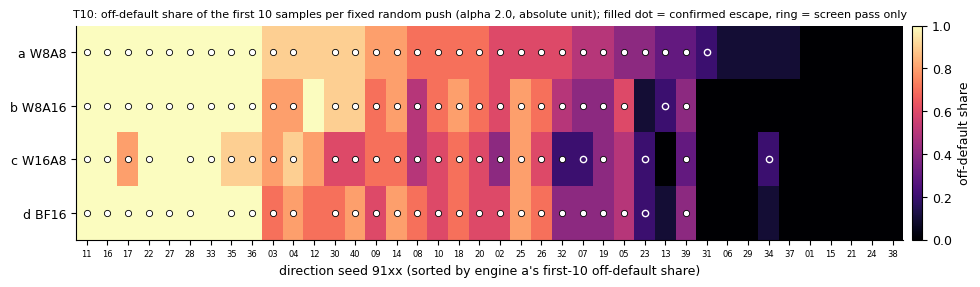

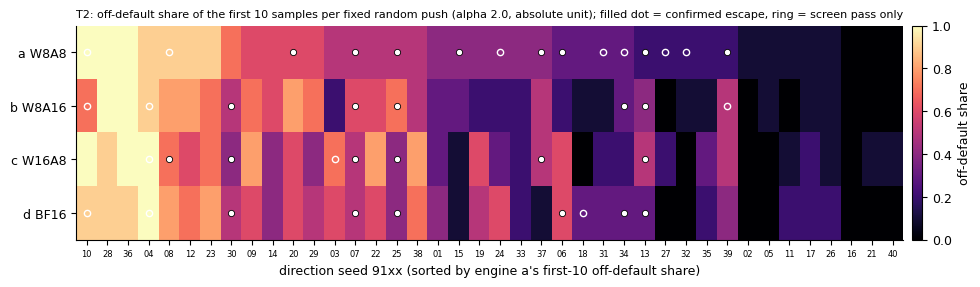

In [24]:
def heatmaps(ESC, alpha: str = "2.0") -> None:
    for t in ("T10", "T2"):
        engs = [e for e in ("a", "b", "c", "d") if e in ESC and t in ESC[e] and alpha in ESC[e][t]["alpha"]]
        if len(engs) < (1 if alpha == "2.0" else 2):
            continue
        pa = ESC["a"][t]["alpha"][alpha]["per_direction"]
        order = sorted(SEEDS_POP, key=lambda s: -(pa[str(s)]["share10"] if pa.get(str(s)) else -1))
        M = np.full((len(engs), len(order)), np.nan)
        fig, ax = plt.subplots(figsize=(11, 1.1 + 0.42 * len(engs)))
        for i, e in enumerate(engs):
            pd = ESC[e][t]["alpha"][alpha]["per_direction"]
            for j, s in enumerate(order):
                c = pd.get(str(s))
                if c is None:
                    continue
                M[i, j] = c["share10"]
                if c["confirmed"]:
                    ax.plot(j, i, marker="o", ms=4.5, color="white", mec="black", mew=0.6)
                elif c["screen"]:
                    ax.plot(j, i, marker="o", ms=4.5, color="none", mec="white", mew=1.0)
        cm = plt.get_cmap("magma").copy()
        cm.set_bad("#dddddd")
        im = ax.imshow(np.ma.masked_invalid(M), aspect="auto", cmap=cm, vmin=0, vmax=1, zorder=0)
        ax.set_yticks(range(len(engs)), [NAME[e] for e in engs])
        ax.set_xticks(range(len(order)), [str(s)[-2:] for s in order], fontsize=6)
        ax.set_xlabel("direction seed 91xx (sorted by engine a's first-10 off-default share)")
        ax.set_title(f"{t}: off-default share of the first 10 samples per fixed random push (alpha {alpha}, absolute unit);"
                     f" filled dot = confirmed escape, ring = screen pass only", fontsize=8)
        fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01, label="off-default share")
        save(fig, f"heatmap_directions_{t}" + ("" if alpha == "2.0" else f"_alpha{alpha}"))


heatmaps(ESCAPES)

### Escape fraction per engine, and per-direction agreement

The first figure shows E per engine with Wilson 95% intervals:
- **Filled markers:** the confirmed E.
- **Open markers:** the screen-level E.

The scatter plots compare per-direction first-10 shares between engines; the points lie close to the diagonal.

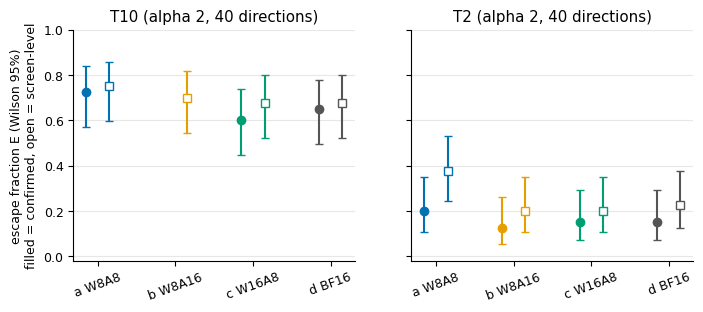

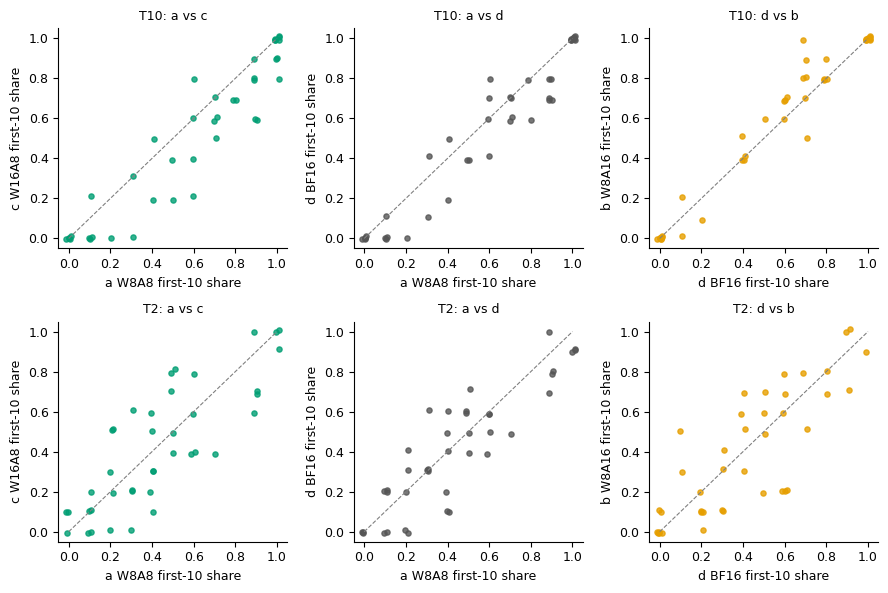

In [25]:
def e_by_engine(ESC) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
    for ax, t in zip(axes, ("T10", "T2")):
        for i, e in enumerate(("a", "b", "c", "d")):
            v = ESC.get(e, {}).get(t, {}).get("alpha", {}).get("2.0")
            if not v:
                continue
            for off, key, wk, mk in ((-0.15, "E_t", "E_wilson", "o"), (0.15, "E_screen", "E_screen_wilson", "s")):
                if key == "E_t" and not v["confirmation_complete"]:
                    continue
                y = v[key]
                lo, hi = v[wk]
                ax.errorbar(i + off, y, yerr=[[y - lo], [hi - y]], fmt=mk, color=COL[e], capsize=3,
                            mfc=COL[e] if key == "E_t" else "white")
        ax.set_xticks(range(4), [NAME[e] for e in ("a", "b", "c", "d")], rotation=20)
        ax.set_title(f"{t} (alpha 2, 40 directions)")
        ax.set_ylim(-0.02, 1.0)
        ax.grid(axis="y", alpha=0.3)
    axes[0].set_ylabel("escape fraction E (Wilson 95%)\nfilled = confirmed, open = screen-level")
    save(fig, "E_by_engine")


def scatter(ESC) -> None:
    pairs = [("a", "c"), ("a", "d"), ("d", "b")]
    fig, axes = plt.subplots(2, 3, figsize=(9, 6))
    for r, t in enumerate(("T10", "T2")):
        for k, (x, y) in enumerate(pairs):
            ax = axes[r, k]
            if x not in ESC or y not in ESC or t not in ESC[x] or t not in ESC[y]:
                ax.set_axis_off()
                continue
            px = ESC[x][t]["alpha"]["2.0"]["per_direction"]
            py = ESC[y][t]["alpha"]["2.0"]["per_direction"]
            xs, ys = [], []
            for s in SEEDS_POP:
                if px.get(str(s)) and py.get(str(s)):
                    xs.append(px[str(s)]["share10"])
                    ys.append(py[str(s)]["share10"])
            rng = np.random.default_rng(0)
            ax.scatter(np.array(xs) + rng.uniform(-0.012, 0.012, len(xs)), np.array(ys) + rng.uniform(-0.012, 0.012, len(ys)),
                       s=14, color=COL[y], alpha=0.8)
            ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=0.8)
            ax.set_xlim(-0.05, 1.05)
            ax.set_ylim(-0.05, 1.05)
            ax.set_xlabel(f"{NAME[x]} first-10 share")
            ax.set_ylabel(f"{NAME[y]} first-10 share")
            ax.set_title(f"{t}: {x} vs {y}", fontsize=9)
    fig.tight_layout()
    save(fig, "per_direction_scatter")


e_by_engine(ESCAPES)
scatter(ESCAPES)

### Per-sample plan noise and landing algorithms

- **First figure:** PN off-default share per engine, beside exp19's FP8 rows.
- **Second figure:** the algorithms that the correct off-default programs use. On T10 these are DFS, then BFS; on T2,
  Bellman-Ford/SPFA. The composition is the same in every engine.

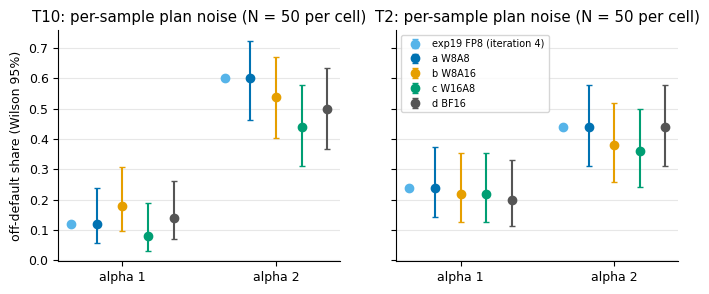

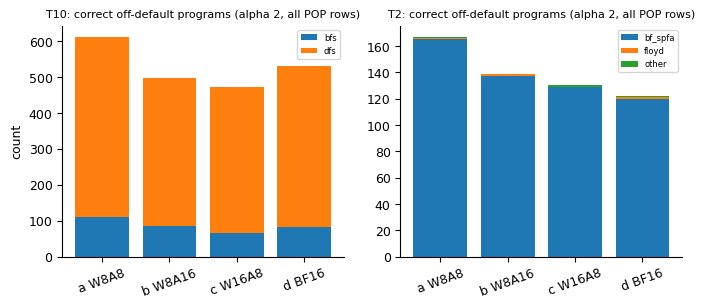

In [26]:
def pn_fig(PN) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
    for ax, t in zip(axes, ("T10", "T2")):
        for j, a in enumerate(("PN_a1", "PN_a2")):
            cell = PN.get(t, {}).get(a, {})
            for i, e in enumerate(("exp19_fp8", "a", "b", "c", "d")):
                v = cell.get(e)
                if not v or not v.get("n_valid"):
                    continue
                y = v["share"]
                lo, hi = v.get("wilson") or (y, y)
                x = j * 6 + i
                ax.errorbar(x, y, yerr=[[y - lo], [hi - y]], fmt="o", color=COL[e], capsize=2,
                            label=(NAME.get(e, "exp19 FP8 (iteration 4)") if j == 0 else None))
        ax.set_xticks([2, 8], ["alpha 1", "alpha 2"])
        ax.set_title(f"{t}: per-sample plan noise (N = 50 per cell)")
        ax.grid(axis="y", alpha=0.3)
    axes[0].set_ylabel("off-default share (Wilson 95%)")
    axes[1].legend(fontsize=7, loc="upper left")
    save(fig, "pn_by_engine")


def landings_fig(L) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(8, 3))
    for ax, t in zip(axes, ("T10", "T2")):
        comp = L.get(t, {}).get("composition_correct_offdefault", {})
        labs = L.get(t, {}).get("labels", [])
        bottom = np.zeros(4)
        cols = plt.get_cmap("tab10")
        for k, lab in enumerate(labs):
            vals = np.array([comp.get(e, {}).get(lab, 0) for e in ("a", "b", "c", "d")], float)
            ax.bar(range(4), vals, bottom=bottom, color=cols(k % 10), label=lab)
            bottom += vals
        ax.set_xticks(range(4), [NAME[e] for e in ("a", "b", "c", "d")], rotation=20)
        ax.set_title(f"{t}: correct off-default programs (alpha 2, all POP rows)", fontsize=8)
        ax.legend(fontsize=6)
    axes[0].set_ylabel("count")
    save(fig, "landings")


pn_fig(PN)
landings_fig(L)

### Activation-space diagnostics, measured on Qwen3-8B on the GPU

These curves come from teacher-forced passes of an α-2 push against its twin, block by block (blocks 12–23 shaded).
They were measured in the artifact's GPU steps and are shipped in the demo data.

- **Induced perturbation.** The **non-nominal** part of the hidden-state change, ‖(h_push − h_twin) − nominal‖, at:
  - the task-spec positions S,
  - the last prompt position R,
  - the generated positions 1–32.

  The curves of all four engines coincide on a log scale, so the extra rounding barely changes how the push
  propagates.
- **e4m3 rounding.** The three metrics of the toy cell above, at the four linear-input sites of every block, measured
  in the W8A8 passes.

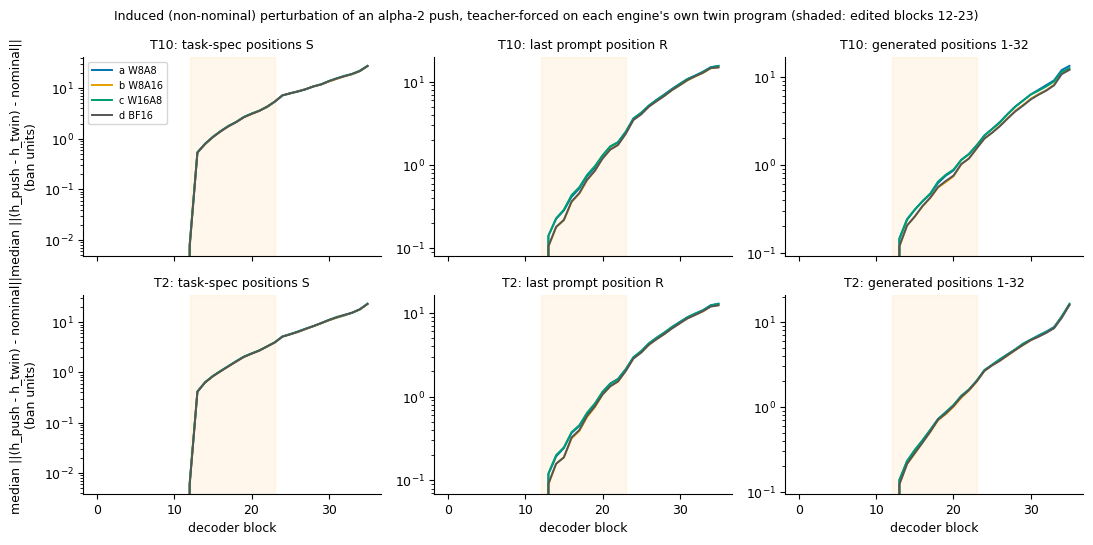

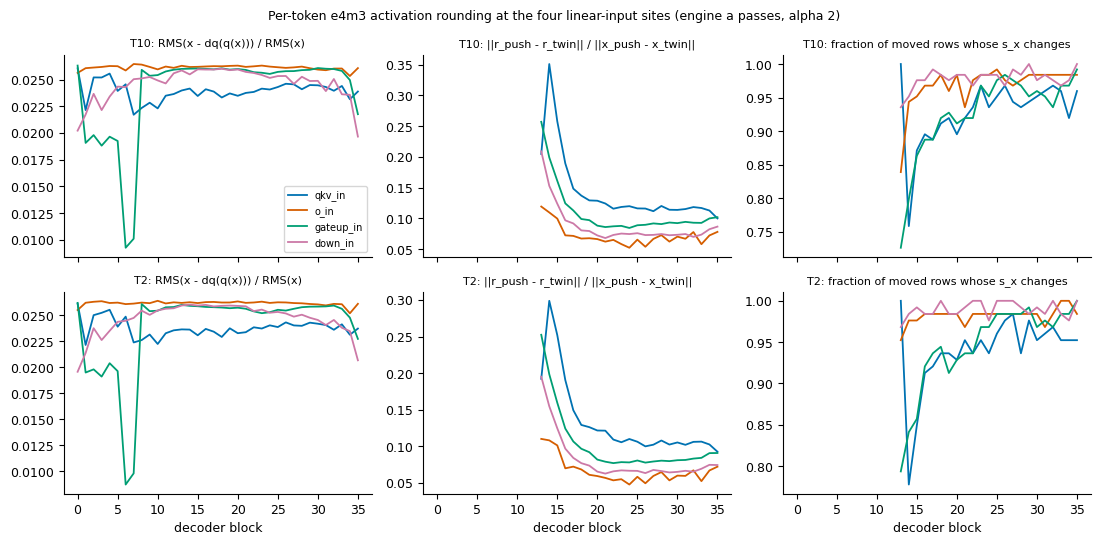

In [27]:
def induced() -> None:
    D = {}
    for ws in ("B", "Q"):
        p = ws  # original: RESULTS / f"diagnostics_{ws}.json" (GPU output; shipped slimmed as META["diagnostics"])
        if p in DIAG:
            d = DIAG[p]
            for k, v in d.items():
                if k.startswith("induced_") and isinstance(v, dict):
                    D[k.split("_")[1]] = v
    if not D:
        return
    fig, axes = plt.subplots(2, 3, figsize=(11, 5.5), sharex=True)
    for r, t in enumerate(("T10", "T2")):
        for k, (g, lab) in enumerate((("S", "task-spec positions S"), ("R", "last prompt position R"),
                                      ("G", "generated positions 1-32"))):
            ax = axes[r, k]
            for e, v in sorted(D.items()):
                if t not in v:
                    continue
                y = [np.nan if z is None else z for z in v[t]["induced_ban_units"][g]]
                ax.plot(range(len(y)), y, color=COL.get(e, "k"), label=NAME.get(e, e), lw=1.4)
            ax.axvspan(12, 23, color="orange", alpha=0.08)
            ax.set_yscale("log")
            ax.set_title(f"{t}: {lab}", fontsize=9)
            if r == 1:
                ax.set_xlabel("decoder block")
            if k == 0:
                ax.set_ylabel("median ||(h_push - h_twin) - nominal||\n(ban units)")
    axes[0, 0].legend(fontsize=7)
    fig.suptitle("Induced (non-nominal) perturbation of an alpha-2 push, teacher-forced on each engine's own twin "
                 "program (shaded: edited blocks 12-23)", fontsize=9)
    fig.tight_layout()
    save(fig, "induced_perturbation")


def rounding() -> None:
    D = {}
    for ws in ("B", "Q"):
        p = ws  # original: RESULTS / f"diagnostics_{ws}.json" (GPU output; shipped slimmed as META["diagnostics"])
        if p in DIAG:
            d = DIAG[p]
            for k, v in d.items():
                if k.startswith("induced_") and isinstance(v, dict):
                    D[k.split("_")[1]] = v
    if not D:
        return
    e0 = "a" if "a" in D else sorted(D)[0]
    fig, axes = plt.subplots(2, 3, figsize=(11, 5.5), sharex=True)
    for r, t in enumerate(("T10", "T2")):
        if t not in D[e0]:
            continue
        rd = D[e0][t]["rounding"]
        for k, (key, lab) in enumerate((("rel_rms", "RMS(x - dq(q(x))) / RMS(x)"),
                                        ("amp", "||r_push - r_twin|| / ||x_push - x_twin||"),
                                        ("scale_changed", "fraction of moved rows whose s_x changes"))):
            ax = axes[r, k]
            for s, col in zip(("qkv_in", "o_in", "gateup_in", "down_in"), ("#0072B2", "#D55E00", "#009E73", "#CC79A7")):
                y = [np.nan if z is None else z for z in rd[s][key]]
                ax.plot(range(len(y)), y, color=col, label=s, lw=1.3)
            ax.set_title(f"{t}: {lab}", fontsize=8)
            if r == 1:
                ax.set_xlabel("decoder block")
    axes[0, 0].legend(fontsize=7)
    fig.suptitle(f"Per-token e4m3 activation rounding at the four linear-input sites (engine {e0} passes, alpha 2)",
                 fontsize=9)
    fig.tight_layout()
    save(fig, "rounding_by_block")


induced()
rounding()

## Results: recomputed versus the artifact's reported numbers

The table below sets every headline recomputed in this notebook beside the value the artifact reported. The reported
values are in `metadata.reference_results` of the demo data. With the original settings (`N_DIRECTIONS = 40`), every
row should match. With fewer directions, the escape and contrast rows are expected to differ, because they are then
computed on a subset. The chart puts the recomputed E per engine (bars) beside the reported values (black ticks).

quantity                                           |        recomputed here |               artifact | match
T10 literal verdict                                |    NOT_REPRODUCED_HIGH |    NOT_REPRODUCED_HIGH | yes
T10 screen-level verdict                           |    NOT_REPRODUCED_HIGH |    NOT_REPRODUCED_HIGH | yes
T10 E (alpha 2) a W8A8                             |                  0.725 |                  0.725 | yes
T10 screen-level E a W8A8                          |                   0.75 |                   0.75 | yes
T10 E (alpha 2) b W8A16                            |                   None |                   None | yes
T10 screen-level E b W8A16                         |                    0.7 |                    0.7 | yes
T10 E (alpha 2) c W16A8                            |                    0.6 |                    0.6 | yes
T10 screen-level E c W16A8                         |                  0.675 |                  0.675 | yes
T10 E (alpha 2) d BF16             

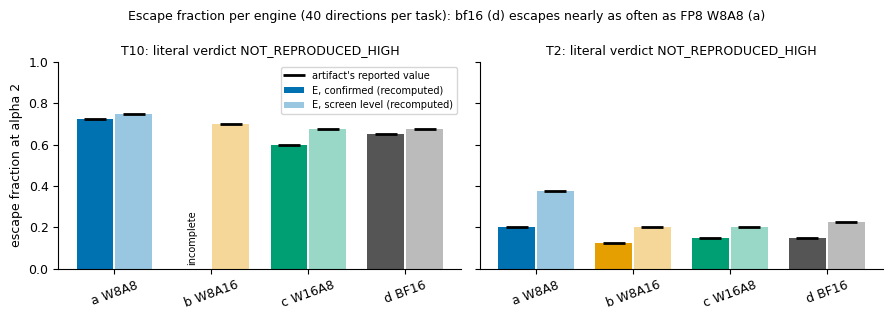

In [28]:
REF = META["reference_results"]
checks = []


def chk(name, mine, ref):
    checks.append((name, mine, ref, mine == ref))


for t in TASKS:
    chk(f"{t} literal verdict", V[t]["literal_verdict"], REF["verdict"][t]["literal_verdict"])
    chk(f"{t} screen-level verdict", V[t]["screen_level_verdict"], REF["verdict"][t]["screen_level_verdict"])
    for e in ENGS:
        chk(f"{t} E (alpha 2) {e} {ENGINES[e]}", V[t]["E_alpha2"][e], REF["verdict"][t]["E_alpha2"][e])
        chk(f"{t} screen-level E {e} {ENGINES[e]}", V[t]["E_screen_alpha2"][e], REF["verdict"][t]["E_screen_alpha2"][e])
for k, ref in REF["mcnemar_directions"].items():
    mine = PAIR.get(k, {})
    chk(f"directions {k} n10:n01", f"{mine.get('n10')}:{mine.get('n01')}", f"{ref['n10']}:{ref['n01']}")
for k, ref in REF["slot_flips_screen"].items():
    mine = SF.get(k, {})
    chk(f"CRN slots {k} n10:n01", f"{mine.get('n10')}:{mine.get('n01')}", f"{ref['n10']}:{ref['n01']}")
for t in TASKS:
    for a, cell in REF["pn_off_default"][t].items():
        for e, ref in cell.items():
            v = PN.get(t, {}).get(a, {}).get(e)
            chk(f"PN {t} {a} {e}", f"{v['k_off']}/{v['n_valid']}" if v else None, ref)
    chk(f"landings top-1 {t}", L[t]["top1"], REF["landings_top1"][t])
chk("rederive: all re-derived fields match the analysis", RD["all_match"], True)

w = max(len(c[0]) for c in checks)
print(f"{'quantity':{w}s} | {'recomputed here':>22s} | {'artifact':>22s} | match")
for name, mine, ref, ok in checks:
    print(f"{name:{w}s} | {str(mine):>22.22s} | {str(ref):>22.22s} | {'yes' if ok else 'NO'}")
n_ok = sum(c[3] for c in checks)
print(f"\n{n_ok}/{len(checks)} recomputed quantities equal the artifact's reported values"
      + ("" if N_DIRECTIONS == 40 else f"  (N_DIRECTIONS = {N_DIRECTIONS} < 40: escape/contrast rows use a subset)"))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, t in zip(axes, TASKS):
    for i, e in enumerate(ENGS):
        mine_c, mine_s = V[t]["E_alpha2"][e], V[t]["E_screen_alpha2"][e]
        ref_c, ref_s = REF["verdict"][t]["E_alpha2"][e], REF["verdict"][t]["E_screen_alpha2"][e]
        ax.bar(i - 0.2, mine_c or 0, 0.38, color=COL[e], label="E, confirmed (recomputed)" if i == 0 else None)
        ax.bar(i + 0.2, mine_s or 0, 0.38, color=COL[e], alpha=0.4, label="E, screen level (recomputed)" if i == 0 else None)
        for x_, r_ in ((i - 0.2, ref_c), (i + 0.2, ref_s)):
            if r_ is not None:
                ax.plot(x_, r_, "k_", ms=16, mew=2, label="artifact's reported value" if (i == 0 and x_ < i) else None)
        if mine_c is None:
            ax.text(i - 0.2, 0.02, "incomplete", rotation=90, ha="center", va="bottom", fontsize=7)
    ax.set_xticks(range(4), [NAME[e] for e in ENGS], rotation=20)
    ax.set_title(f"{t}: literal verdict {V[t]['literal_verdict']}", fontsize=9)
    ax.set_ylim(0, 1)
axes[0].set_ylabel("escape fraction at alpha 2")
axes[0].legend(fontsize=7, loc="upper right")
fig.suptitle(f"Escape fraction per engine ({N_DIRECTIONS} directions per task): bf16 (d) escapes nearly as often as "
             f"FP8 W8A8 (a)", fontsize=9)
fig.tight_layout()
plt.show()

## Takeaways

- **The escapes are a model property, not an FP8 artifact.** At the same absolute push, bf16 (d) escapes on nearly
  the same directions as the iteration-4 W8A8 engine (a):
  - T10: E 0.725 vs 0.650, discordance 3:0, κ 0.83, Spearman 0.96;
  - T2: E 0.200 vs 0.150.

  The pre-registered verdict is **NOT_REPRODUCED_HIGH** on both tasks.
- **FP8 adds only a small per-slot boost, on T10.** CRN-paired screen slots are off-default 58.3% of the time under
  W8A8 vs 53.2% under bf16 (30:10, p = 0.0022). Weight rounding carries part of this boost (b: 55.6%); activation
  rounding alone does not (c: 49.7%).
- **Per-sample plan noise reproduces in bf16 at the matched unit.** On T10 at α 2: a 30/50, d 25/50. Iteration 5's
  bf16 null came from its different unit and seeds.
- **The mechanism diagnostics agree.** e4m3 rounding perturbs each linear input by about 2.5% RMS. The extra rounding
  barely changes how a push propagates: induced-perturbation ratios to bf16 are about 1.0–1.13. Per-token KL to bf16
  is at most 0.004 nats.

**To reproduce the generation itself**, see the artifact's `reproducibility.md`. You need Qwen3-8B (revision
`b968826d`), one ≥ 16 GB CUDA GPU (sm_89+ for engine a's native FP8 kernel), the pinned `pyproject.toml`, and then
`uv run method.py all`.